<a href="https://colab.research.google.com/github/suryamanoj4/smai-a5/blob/main/SMAI_A5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Install dependencies
!pip install -q kaggle torch torchvision torchmetrics \
    pandas numpy matplotlib seaborn pillow tqdm \
    scikit-learn imagehash python-dotenv

In [2]:
import os
from getpass import getpass

KAGGLE_USERNAME = input("Enter Kaggle username: ")
KAGGLE_KEY = getpass("Enter Kaggle API key: ")

env_content = f"""
KAGGLE_USERNAME={KAGGLE_USERNAME}
KAGGLE_KEY={KAGGLE_KEY}
"""

with open("/content/.env", "w") as f:
    f.write(env_content)

print(".env file created successfully!")

Enter Kaggle username: suryamanoj4
Enter Kaggle API key: ··········
.env file created successfully!


In [3]:
from dotenv import load_dotenv
import os
import json

load_dotenv("/content/.env")

KAGGLE_USERNAME = os.getenv("KAGGLE_USERNAME")
KAGGLE_KEY = os.getenv("KAGGLE_KEY")

if not KAGGLE_USERNAME or not KAGGLE_KEY:
    raise ValueError("Kaggle credentials not found!")

os.makedirs("/root/.kaggle", exist_ok=True)

kaggle_config = {
    "username": KAGGLE_USERNAME,
    "key": KAGGLE_KEY
}

with open("/root/.kaggle/kaggle.json", "w") as f:
    json.dump(kaggle_config, f)

os.chmod("/root/.kaggle/kaggle.json", 0o600)

print("Kaggle authentication configured!")

Kaggle authentication configured!


In [4]:
import os
import zipfile
from pathlib import Path

DATASET_NAME = "sayehkargari/disney-characters-dataset"
DOWNLOAD_DIR = "/content/dataset"
EXTRACT_DIR = "/content/disney_dataset"
os.makedirs(DOWNLOAD_DIR, exist_ok=True)
os.makedirs(EXTRACT_DIR, exist_ok=True)

!kaggle datasets download \
    -d sayehkargari/disney-characters-dataset \
    -p /content/dataset

zip_files = list(Path(DOWNLOAD_DIR).glob("*.zip"))

if not zip_files:
    raise FileNotFoundError("Dataset download failed!")

with zipfile.ZipFile(zip_files[0], "r") as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print("Dataset downloaded and extracted successfully!")

Dataset URL: https://www.kaggle.com/datasets/sayehkargari/disney-characters-dataset
License(s): unknown
100% 609M/609M [00:05<00:00, 127MB/s]

Dataset downloaded and extracted successfully!


In [5]:
!du -sh /content/disney_dataset
!find /content/disney_dataset -maxdepth 3 -type d

641M	/content/disney_dataset
/content/disney_dataset
/content/disney_dataset/cartoon
/content/disney_dataset/cartoon/train
/content/disney_dataset/cartoon/train/pumba
/content/disney_dataset/cartoon/train/mickey
/content/disney_dataset/cartoon/train/pooh
/content/disney_dataset/cartoon/train/minion
/content/disney_dataset/cartoon/train/olaf
/content/disney_dataset/cartoon/train/donald
/content/disney_dataset/cartoon/test
/content/disney_dataset/cartoon/test/pumba
/content/disney_dataset/cartoon/test/mickey
/content/disney_dataset/cartoon/test/pooh
/content/disney_dataset/cartoon/test/minion
/content/disney_dataset/cartoon/test/olaf
/content/disney_dataset/cartoon/test/donald


In [6]:
# question 1 CNNs part A

import os
import random
import hashlib
import shutil
import warnings
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image, ImageFile, UnidentifiedImageError
from tqdm.auto import tqdm

import torch
from torchvision import datasets
from torchvision.datasets.folder import IMG_EXTENSIONS
import imagehash

warnings.filterwarnings("ignore")

SEED = 36
random.seed(SEED)
np.random.seed(SEED)

CLASSES = [
    "donald",
    "mickey",
    "minion",
    "olaf",
    "pooh",
    "pumba"
]
SPLITS = ["train", "test"]

dataset_root = Path("/content/disney_dataset/cartoon")
TEST_DIR = dataset_root/"test"
TRAIN_DIR = dataset_root/"train"

assert TRAIN_DIR.exists(), f"Missing directory: {TRAIN_DIR}"
assert TEST_DIR.exists(), f"Missing directory: {TEST_DIR}"

AUDIT_DIR = Path("/content/audit_results")
CLEANED_DIR = Path("/content/disney_cleaned")
AUDIT_DIR.mkdir(parents=True, exist_ok=True)
CLEANED_DIR.mkdir(parents=True, exist_ok=True)

EMAIL_USERNAME = "manoj.pentakota"

TARGET_SIZE = (64, 64)
BACKGROUND_COLOR = (255, 255, 255)

print("Configuration completed.")
print("Classes:", CLASSES)
print("Training directory:", TRAIN_DIR)
print("Testing directory:", TEST_DIR)


Configuration completed.
Classes: ['donald', 'mickey', 'minion', 'olaf', 'pooh', 'pumba']
Training directory: /content/disney_dataset/cartoon/train
Testing directory: /content/disney_dataset/cartoon/test


In [7]:
class DatasetAuditor:
    """
    audits the dataset
    """

    def __init__(self, train_dir, test_dir, classes):
        self.split_dirs = {
            "train": Path(train_dir),
            "test": Path(test_dir)
        }

        self.classes = classes
        self.inventory = None
        self.decode_results = None
        self.image_metadata = None

    def get_files(self, split, class_name):
        class_dir = self.split_dirs[split] / class_name
        if not class_dir.exists():
            return []
        return [
            p for p in class_dir.rglob("*")
            if p.is_file()
        ]

    def get_file_hash(self, file_path):
        sha256 = hashlib.sha256()
        with open(file_path, "rb") as f:
            for chunk in iter(lambda: f.read(8192), b""):
                sha256.update(chunk)
        return sha256.hexdigest()

    def inventory_files(self):
        """
        counts files per split, class and extension.
        slso identifies hidden files and unsupported extensions.
        """
        records = []
        for split in SPLITS:
            for class_name in self.classes:
                files = self.get_files(split, class_name)
                for file_path in files:
                    extension = file_path.suffix.lower()
                    records.append({
                        "split": split,
                        "class": class_name,
                        "filename": file_path.name,
                        "path": str(file_path),
                        "extension": extension if extension else "[no extension]",
                        "is_hidden": file_path.name.startswith("."),
                        "is_supported_by_imagefolder":
                            extension in IMG_EXTENSIONS
                    })
        self.inventory = pd.DataFrame(records)
        return self.inventory

    def get_inventory_summary(self):
        if self.inventory is None:
            self.inventory_files()

        summary = (
            self.inventory
            .groupby(["split", "class"])
            .size()
            .unstack(fill_value=0)
        )
        extension_summary = (
            self.inventory
            .groupby(["split", "extension"])
            .size()
            .unstack(fill_value=0)
        )
        split_summary = (
            self.inventory
            .groupby("split")
            .size()
            .rename("total_files")
        )
        return summary, extension_summary, split_summary

    def compare_imagefolder(self):
        """
        compare our inventory againt torchvision ImageFolder.
        ImageFolder only recognises supported image extensions.
        """
        results = []
        for split, directory in self.split_dirs.items():
            dataset = datasets.ImageFolder(str(directory))
            our_count = len(
                self.inventory[
                    (self.inventory["split"] == split) &
                    (self.inventory["is_supported_by_imagefolder"])
                ]
            )
            results.append({
                "split": split,
                "our_supported_file_count": our_count,
                "imagefolder_count": len(dataset),
                "difference": our_count - len(dataset)
            })
        return pd.DataFrame(results)

    def inspect_image(self, file_path):
        """
        fully decode an image. first attempts strict decoding.
        if that fails, retries with truncated-image support enabled.
        for GIFs, checks all frames.
        """
        result = {
            "path": str(file_path),
            "status": None,
            "width": None,
            "height": None,
            "mode": None,
            "format": None,
            "n_frames": None,
            "is_animated": False,
            "was_truncated": False,
            "error": None
        }
        try:
            ImageFile.LOAD_TRUNCATED_IMAGES = False
            with Image.open(file_path) as img:
                result["format"] = img.format
                result["width"], result["height"] = img.size
                result["mode"] = img.mode
                result["n_frames"] = getattr(img, "n_frames", 1)
                result["is_animated"] = result["n_frames"] > 1
                for frame_index in range(result["n_frames"]):
                    img.seek(frame_index)
                    img.load()
            result["status"] = "valid"
        except Exception as strict_error:
            try:
                ImageFile.LOAD_TRUNCATED_IMAGES = True
                with Image.open(file_path) as img:
                    result["format"] = img.format
                    result["width"], result["height"] = img.size
                    result["mode"] = img.mode
                    result["n_frames"] = getattr(img, "n_frames", 1)
                    result["is_animated"] = result["n_frames"] > 1
                    for frame_index in range(result["n_frames"]):
                        img.seek(frame_index)
                        img.load()

                result["status"] = "truncated_recoverable"
                result["was_truncated"] = True

            except Exception as tolerant_error:
                if isinstance(
                    tolerant_error,
                    (UnidentifiedImageError, IsADirectoryError)
                ):
                    result["status"] = "not_image"
                else:
                    result["status"] = "corrupted"
                result["error"] = str(tolerant_error)
        finally:
            ImageFile.LOAD_TRUNCATED_IMAGES = False
        return result

    def audit_readability(self):
        """
        attempt to decode every file and collect the image metadata
        """
        if self.inventory is None:
            self.inventory_files()
        results = []
        for _, row in tqdm(
            self.inventory.iterrows(),
            total=len(self.inventory),
            desc="Auditing files"
        ):
            result = self.inspect_image(row["path"])
            result.update({
                "split": row["split"],
                "class": row["class"],
                "filename": row["filename"],
                "extension": row["extension"]
            })
            results.append(result)
        self.decode_results = pd.DataFrame(results)
        self.image_metadata = self.decode_results[
            self.decode_results["status"].isin(
                ["valid", "truncated_recoverable"]
            )
        ].copy()
        return self.decode_results

    def get_readability_summary(self):
        return (
            self.decode_results
            .groupby(["split", "status"])
            .size()
            .unstack(fill_value=0)
        )

    def get_gif_summary(self):
        """report GIF counts and animated GIF counts."""

        gif_data = self.decode_results[
            self.decode_results["extension"] == ".gif"
        ]
        return pd.DataFrame({
            "total_gifs": [
                len(gif_data)
            ],
            "animated_gifs": [
                gif_data["is_animated"].sum()
            ],
            "static_gifs": [
                (~gif_data["is_animated"]).sum()
            ]
        })


In [8]:
auditor = DatasetAuditor(
    train_dir=TRAIN_DIR,
    test_dir=TEST_DIR,
    classes=CLASSES
)

# generate the file inventory
inventory_df = auditor.inventory_files()

print("Total files found:", len(inventory_df))

# save inventory
inventory_df.to_csv(
    AUDIT_DIR / "file_inventory.csv",
    index=False
)

# generate summaries
class_summary, extension_summary, split_summary = (
    auditor.get_inventory_summary()
)

print("\nFiles per split:")
display(split_summary.to_frame())

print("\nFiles per split and class:")
display(class_summary)

print("\nFiles per extension:")
display(extension_summary)


Total files found: 4667

Files per split:


,total_files
split,
test,512
train,4155



Files per split and class:


class,donald,mickey,minion,olaf,pooh,pumba
split,,,,,,
test,109,104,72,87,79,61
train,642,725,710,617,764,697



Files per extension:


extension,.gif,.jpeg,.jpg,.png,[no extension]
split,,,,,
test,79,21,146,266,0
train,631,366,2022,1135,1


In [9]:
# files not recognised by torchvision ImageFolder
unsupported_files = inventory_df[
    ~inventory_df["is_supported_by_imagefolder"]
].copy()

# now hiidden files
hidden_files = inventory_df[
    inventory_df["is_hidden"]
].copy()

print("Unsupported files:", len(unsupported_files))
print("Hidden files:", len(hidden_files))
print("\nUnsupported extension distribution:")

if len(unsupported_files) > 0:
    display(
        unsupported_files.groupby("extension")
        .size()
        .reset_index(name="count")
        .sort_values("count", ascending=False)
    )

print("\nHidden files:")
display(hidden_files[["split", "class", "filename", "path"]].head(30))

# save reports
unsupported_files.to_csv(
    AUDIT_DIR / "unsupported_files.csv",
    index=False
)

hidden_files.to_csv(
    AUDIT_DIR / "hidden_files.csv",
    index=False
)

Unsupported files: 711
Hidden files: 1

Unsupported extension distribution:


,extension,count
0,.gif,710
1,[no extension],1



Hidden files:


,split,class,filename,path
332,train,donald,.jpg,/content/disney_dataset/cartoon/train/donald/.jpg


In [10]:
imagefolder_comparison = auditor.compare_imagefolder()

print("our inventoiry vs torchvision ImageFolder")
display(imagefolder_comparison)

our inventoiry vs torchvision ImageFolder


,split,our_supported_file_count,imagefolder_count,difference
0,train,3523,3524,-1
1,test,433,433,0


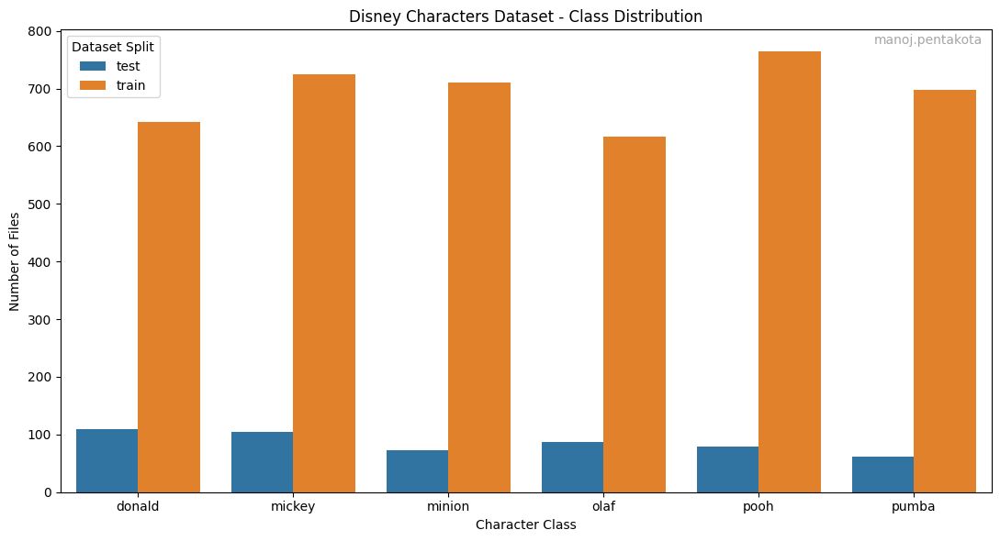

In [11]:
def plot_class_distribution(inventory):
    """plot the number of files per class in each split"""

    counts = (
        inventory
        .groupby(["class", "split"])
        .size()
        .reset_index(name="count")
    )
    plt.figure(figsize=(11, 6))
    sns.barplot(
        data=counts,
        x="class",
        y="count",
        hue="split"
    )
    plt.title("Disney Characters Dataset - Class Distribution")
    plt.xlabel("Character Class")
    plt.ylabel("Number of Files")
    plt.legend(title="Dataset Split")
    plt.text(
        0.99, 0.99, EMAIL_USERNAME,
        ha="right", va="top",
        transform=plt.gca().transAxes,
        fontsize=10, color="gray", alpha=0.7
    )
    plt.tight_layout()
    plt.savefig(
        AUDIT_DIR / "class_distribution.png",
        dpi=300
    )
    plt.show()

plot_class_distribution(inventory_df)

In [12]:
decode_df = auditor.audit_readability()

decode_df.to_csv(
    AUDIT_DIR / "readability_report.csv",
    index=False
)
print("Readability audit completed!")
print("\nReadability summary:")
display(auditor.get_readability_summary())
print("\nFiles requiring attention:")
problematic_files = decode_df[
    decode_df["status"] != "valid"
]
display(
    problematic_files[
        [
            "split",
            "class",
            "filename",
            "status",
            "error"
        ]
    ].head(50)
)

Auditing files:   0%|          | 0/4667 [00:00<?, ?it/s]

Readability audit completed!

Readability summary:


status,truncated_recoverable,valid
split,,
test,0,512
train,1,4154



Files requiring attention:


,split,class,filename,status,error
265,train,donald,history-donald-duck-personality.jpg,truncated_recoverable,None


In [13]:
gif_summary = auditor.get_gif_summary()

print("GIF Analysis:")
display(gif_summary)
gif_details = decode_df[
    decode_df["extension"] == ".gif"
][
    [
        "split",
        "class",
        "filename",
        "n_frames",
        "is_animated",
        "status"
    ]
]

display(gif_details.head(20))
gif_details.to_csv(
    AUDIT_DIR / "gif_analysis.csv",
    index=False
)

GIF Analysis:


,total_gifs,animated_gifs,static_gifs
0,710,7,703


,split,class,filename,n_frames,is_animated,status
5,train,donald,donald-duck-crabs.gif,1,False,valid
6,train,donald,val13s.gif,1,False,valid
8,train,donald,val42s.gif,1,False,valid
10,train,donald,val39s.gif,1,False,valid
11,train,donald,donaldexcited2s.gif,1,False,valid
16,train,donald,feb264s.gif,1,False,valid
20,train,donald,donskarte.gif,1,False,valid
22,train,donald,donski.gif,1,False,valid
24,train,donald,donald-duck17s.gif,1,False,valid
30,train,donald,fev15s.gif,1,False,valid


In [14]:
mode_summary = (
    auditor.image_metadata
    .groupby(["split", "mode"])
    .size()
    .unstack(fill_value=0)
)

print("image colour mode distribution:")
display(mode_summary)

image colour mode distribution:


mode,CMYK,L,LA,P,RGB,RGBA
split,,,,,,
test,0,0,0,99,297,116
train,2,1,1,993,2636,522


In [15]:
dimension_df = auditor.image_metadata.copy()
dimension_df["aspect_ratio"] = (
    dimension_df["width"] / dimension_df["height"]
)
dimension_df["pixel_count"] = (
    dimension_df["width"] * dimension_df["height"]
)
print("Image dimension statistics:")
display(
    dimension_df[
        ["width", "height", "aspect_ratio", "pixel_count"]
    ].describe()
)
print("\nDimensions by split:")
display(
    dimension_df.groupby("split")[
        ["width", "height", "aspect_ratio"]
    ].describe()
)
dimension_df.to_csv(
    AUDIT_DIR / "image_dimensions.csv",
    index=False
)

Image dimension statistics:


,width,height,aspect_ratio,pixel_count
count,4667.000000,4667.000000,4667.000000,4.667000e+03
mean,602.107564,585.479323,1.069518,6.391607e+05
std,599.838580,558.392690,0.369868,2.162708e+06
min,1.000000,1.000000,0.196246,1.000000e+00
25%,205.000000,214.000000,0.813819,5.037000e+04
50%,490.000000,496.000000,1.000000,2.508800e+05
75%,840.000000,800.000000,1.250000,6.690000e+05
max,9000.000000,8000.000000,3.636364,5.831200e+07



Dimensions by split:


width                                                            \
        count        mean        std   min    25%    50%    75%     max   
split                                                                     
test    512.0  598.916016  384.05831  64.0  236.0  685.0  860.0  2560.0   
train  4155.0  602.500842  621.29548   1.0  201.0  478.0  840.0  9000.0   

       height              ...                 aspect_ratio            \
        count        mean  ...     75%     max        count      mean   
split                      ...                                          
test    512.0  605.679688  ...  823.75  3472.0        512.0  1.052796   
train  4155.0  582.990132  ...  800.00  8000.0       4155.0  1.071578   

                                                              
            std       min       25%  50%       75%       max  
split                                                         
test   0.340442  0.373563  0.800000  1.0  1.266326  2.277778  
train  0.373320  0.196246  0.815261  1.0  1.250000  3.636364  

[2 rows x 24 columns]

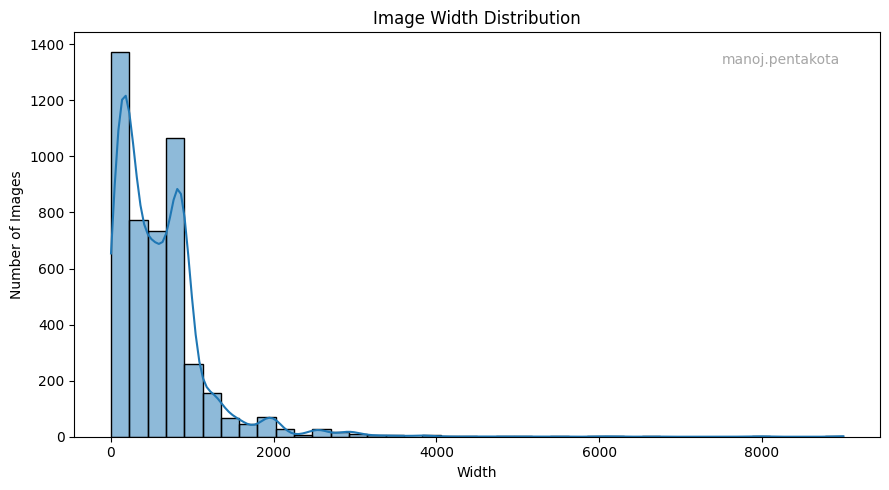

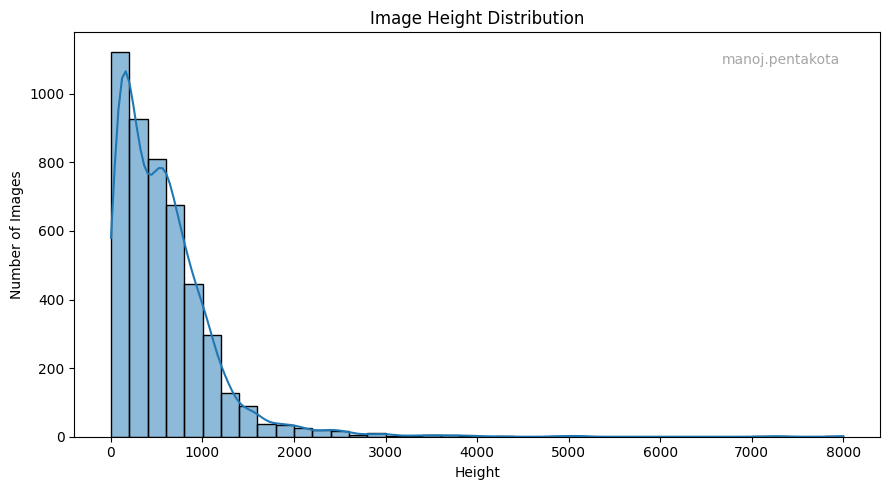

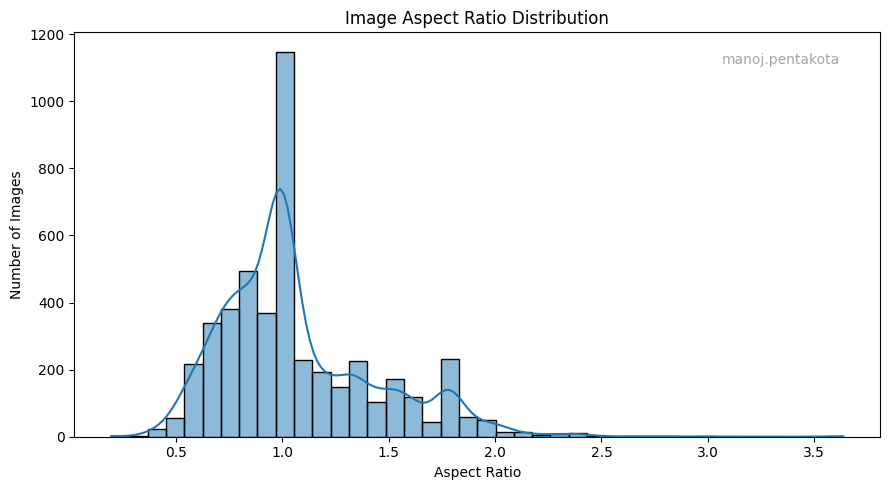

In [16]:
def plot_dimension_distributions(data):
    """plot width, height and aspect ratio distributions"""

    columns = [
        ("width", "Image Width Distribution"),
        ("height", "Image Height Distribution"),
        ("aspect_ratio", "Image Aspect Ratio Distribution")
    ]
    for column, title in columns:
        plt.figure(figsize=(9, 5))
        sns.histplot(
            data=data,
            x=column,
            bins=40,
            kde=True
        )
        plt.title(title)
        plt.xlabel(column.replace("_", " ").title())
        plt.ylabel("Number of Images")
        plt.text(
            0.95, 0.95, EMAIL_USERNAME,
            ha="right", va="top",
            transform=plt.gca().transAxes,
            fontsize=10, color="gray", alpha=0.7
        )
        plt.tight_layout()
        plt.savefig(
            AUDIT_DIR / f"{column}_distribution.png",
            dpi=300
        )
        plt.show()

plot_dimension_distributions(dimension_df)

for the image sizes and aspect ratios

im going with 64*64 as the reference CNN also used the same input images and also this reduces the GPU compute required while leaving us with a chance for future ablations with other dimensions if required

also we are going with aspect ratio preserving resizinf with padding so that the characters wont sufer stretching from direct resizing

In [17]:
def calculate_image_hashes(metadata):
    """
    calcuate hashes for valid images
    """
    records = []
    valid_data = metadata[
        metadata["status"].isin(
            ["valid", "truncated_recoverable"]
        )
    ]
    for _, row in tqdm(
        valid_data.iterrows(),
        total=len(valid_data),
        desc="Calculating hashes"
    ):
        file_path = row["path"]
        try:
            sha256 = auditor.get_file_hash(file_path)
            with Image.open(file_path) as img:
                img.seek(0)
                if img.mode == "RGBA":
                    background = Image.new(
                        "RGBA", img.size, BACKGROUND_COLOR + (255,)
                    )
                    img = Image.alpha_composite(
                        background, img.convert("RGBA")
                    ).convert("RGB")
                else:
                    img = img.convert("RGB")
                phash = imagehash.phash(img)
            records.append({
                "path": file_path,
                "split": row["split"],
                "class": row["class"],
                "filename": row["filename"],
                "sha256": sha256,
                "phash": str(phash),
                "phash_int": int(str(phash), 16)
            })

        except Exception as e:
            print(f"Hashing failed: {file_path} | {e}")
    return pd.DataFrame(records)
hash_df = calculate_image_hashes(decode_df)
hash_df.to_csv(
    AUDIT_DIR / "image_hashes.csv",
    index=False
)
print("Images hashed:", len(hash_df))

Calculating hashes:   0%|          | 0/4667 [00:00<?, ?it/s]

Hashing failed: /content/disney_dataset/cartoon/train/donald/history-donald-duck-personality.jpg | image file is truncated (5 bytes not processed)
Images hashed: 4666


In [18]:
def find_exact_duplicates(hash_data):
    """find groups of files having identical SHA256 hashes"""
    duplicate_groups = (
        hash_data.groupby("sha256")
        .filter(lambda x: len(x) > 1)
        .sort_values("sha256")
    )
    return duplicate_groups

exact_duplicates = find_exact_duplicates(hash_df)
print("Files involved in exact duplicate groups:",
      len(exact_duplicates))

if len(exact_duplicates) > 0:
    print("\nExact duplicate groups:")
    display(
        exact_duplicates[
            ["sha256", "split", "class", "filename", "path"]
        ]
    )
else:
    print("No exact duplicate groups found.")

exact_duplicates.to_csv(
    AUDIT_DIR / "exact_duplicates.csv",
    index=False
)

Files involved in exact duplicate groups: 277

Exact duplicate groups:


,sha256,split,class,filename,path
366,007421f6e90ea1cad8d43d2b967c9084c06ac0f4d9d663...,train,donald,images (12).png,/content/disney_dataset/cartoon/train/donald/i...
142,007421f6e90ea1cad8d43d2b967c9084c06ac0f4d9d663...,train,donald,image (2).png,/content/disney_dataset/cartoon/train/donald/i...
3584,0224a3c26d7df35ab52b6744a0da1569c5728193afa7d9...,train,pumba,4182ab7323f6d6a57480a39ffdbcc3f3--timon-and-pu...,/content/disney_dataset/cartoon/train/pumba/41...
3559,0224a3c26d7df35ab52b6744a0da1569c5728193afa7d9...,train,pumba,4182ab7323f6d6a57480a39ffdbcc3f3.jpg,/content/disney_dataset/cartoon/train/pumba/41...
1039,0255fd292fcd8ddea47c7cc2dd402fbee392f3d8caf4ab...,train,mickey,325-3259091_mickeyicon-mickey-mouse-icon-clipa...,/content/disney_dataset/cartoon/train/mickey/3...
...,...,...,...,...,...
1282,fa32d96be32d1720cf5b38678941407c4f71393f1e5f88...,train,mickey,images11.jpg,/content/disney_dataset/cartoon/train/mickey/i...
3249,fd95acb231064c08d06152ac0d1b44eecae759b236f331...,train,pooh,Winnie-The-Pooh.png,/content/disney_dataset/cartoon/train/pooh/Win...
2860,fd95acb231064c08d06152ac0d1b44eecae759b236f331...,train,pooh,Winnie-the-Pooh-Characters.png,/content/disney_dataset/cartoon/train/pooh/Win...
2569,ffe6ab8f48e32d231dbd35171484d15d011e90f9b4c33e...,train,olaf,images7.jpg,/content/disney_dataset/cartoon/train/olaf/ima...


In [19]:
def find_near_duplicates(hash_data, threshold=6):
    """
    identify cross-split near-duplicate images
    hammming distance less than threshold indicates condidate pair
    """
    train_data = hash_data[
        hash_data["split"] == "train"
    ].reset_index(drop=True)

    test_data = hash_data[
        hash_data["split"] == "test"
    ].reset_index(drop=True)

    candidates = []
    for _, test_row in tqdm(
        test_data.iterrows(),
        total=len(test_data),
        desc="Comparing train-test images"
    ):
        test_hash = int(test_row["phash_int"])
        for _, train_row in train_data.iterrows():
            train_hash = int(train_row["phash_int"])
            distance = (
                test_hash ^ train_hash
            ).bit_count()
            if distance <= threshold:
                candidates.append({
                    "train_path": train_row["path"],
                    "test_path": test_row["path"],
                    "train_class": train_row["class"],
                    "test_class": test_row["class"],
                    "hamming_distance": distance,
                    "same_class": (
                        train_row["class"] == test_row["class"]
                    )
                })

    return pd.DataFrame(candidates)

PHASH_THRESHOLD = 6
near_duplicates = find_near_duplicates(
    hash_df,
    threshold=PHASH_THRESHOLD
)
print("Near-duplicate candidate pairs:",len(near_duplicates))
display(
    near_duplicates.sort_values(
        "hamming_distance"
    ).head(30)
)
near_duplicates.to_csv(
    AUDIT_DIR / "near_duplicate_candidates.csv",
    index=False
)

Comparing train-test images:   0%|          | 0/512 [00:00<?, ?it/s]

Near-duplicate candidate pairs: 310


,train_path,test_path,train_class,test_class,hamming_distance,same_class
3,/content/disney_dataset/cartoon/train/donald/i...,/content/disney_dataset/cartoon/test/donald/do...,donald,donald,0,True
307,/content/disney_dataset/cartoon/train/pumba/Ti...,/content/disney_dataset/cartoon/test/pumba/148...,pumba,pumba,0,True
5,/content/disney_dataset/cartoon/train/donald/i...,/content/disney_dataset/cartoon/test/donald/do...,donald,donald,0,True
4,/content/disney_dataset/cartoon/train/donald/d...,/content/disney_dataset/cartoon/test/donald/do...,donald,donald,0,True
7,/content/disney_dataset/cartoon/train/donald/d...,/content/disney_dataset/cartoon/test/donald/do...,donald,donald,0,True
15,/content/disney_dataset/cartoon/train/donald/3...,/content/disney_dataset/cartoon/test/donald/32...,donald,donald,0,True
13,/content/disney_dataset/cartoon/train/donald/5...,/content/disney_dataset/cartoon/test/donald/51...,donald,donald,0,True
8,/content/disney_dataset/cartoon/train/donald/i...,/content/disney_dataset/cartoon/test/donald/7e...,donald,donald,0,True
57,/content/disney_dataset/cartoon/train/mickey/c...,/content/disney_dataset/cartoon/test/mickey/55...,mickey,mickey,0,True
56,/content/disney_dataset/cartoon/train/mickey/a...,/content/disney_dataset/cartoon/test/mickey/im...,mickey,mickey,0,True


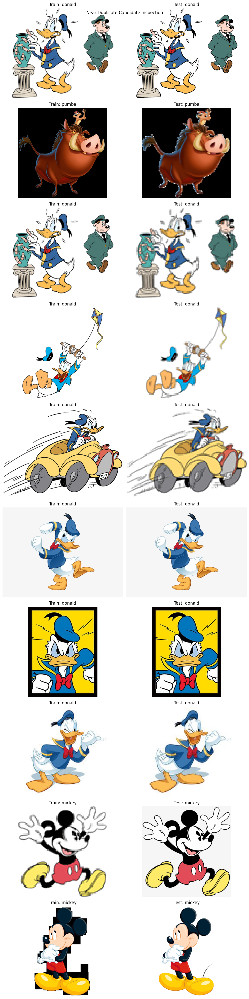

In [20]:
def display_duplicate_pairs(pairs, num_pairs=10):
    """diplay near duplication pair for manual verificatio"""

    if len(pairs) == 0:
        print("No candidate pairs to display.")
        return
    selected = pairs.sort_values("hamming_distance").head(num_pairs)
    fig, axes = plt.subplots(
        len(selected), 2,
        figsize=(10, 4 * len(selected))
    )
    if len(selected) == 1:
        axes = np.array([axes])

    for i, (_, row) in enumerate(selected.iterrows()):
        for j, path in enumerate([
            row["train_path"],
            row["test_path"]
        ]):
            with Image.open(path) as img:
                img.seek(0)
                axes[i, j].imshow(img.convert("RGB"))

            axes[i, j].axis("off")

        axes[i, 0].set_title(
            f"Train: {row['train_class']}"
        )

        axes[i, 1].set_title(
            f"Test: {row['test_class']}"
        )

        axes[i, 0].set_ylabel(
            f"Distance: {row['hamming_distance']}"
        )

    plt.suptitle("Near-Duplicate Candidate Inspection")
    plt.tight_layout()
    plt.show()

display_duplicate_pairs(
    near_duplicates,
    num_pairs=10
)

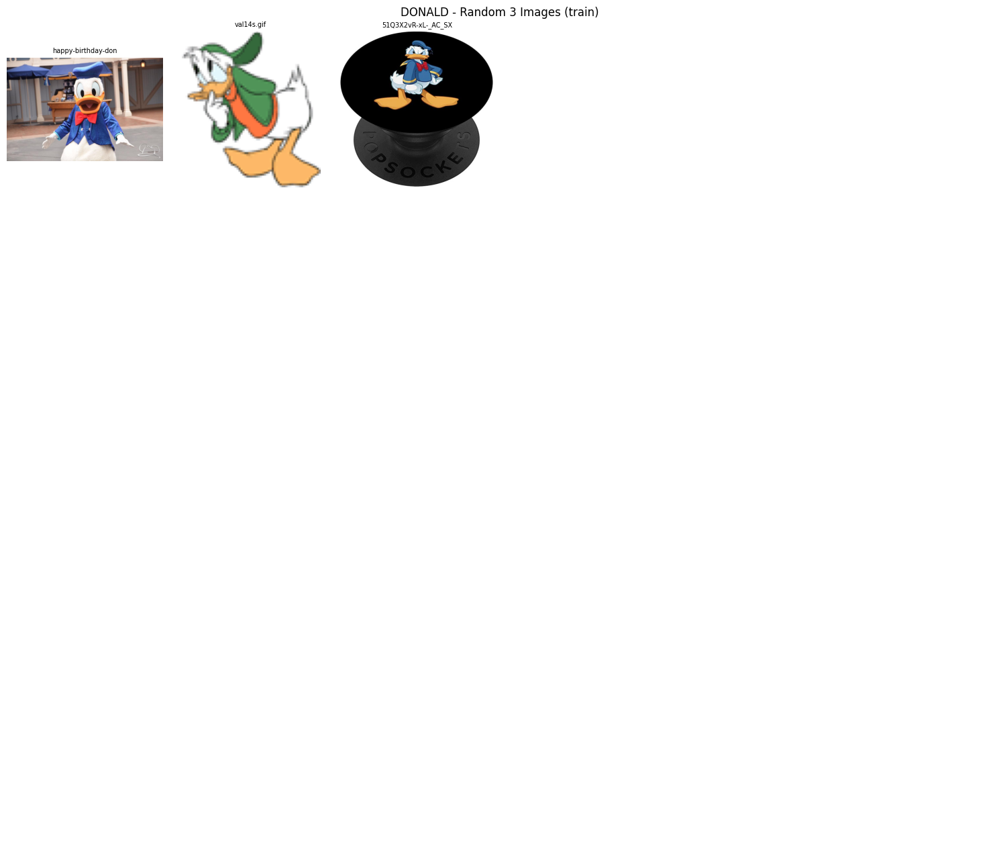

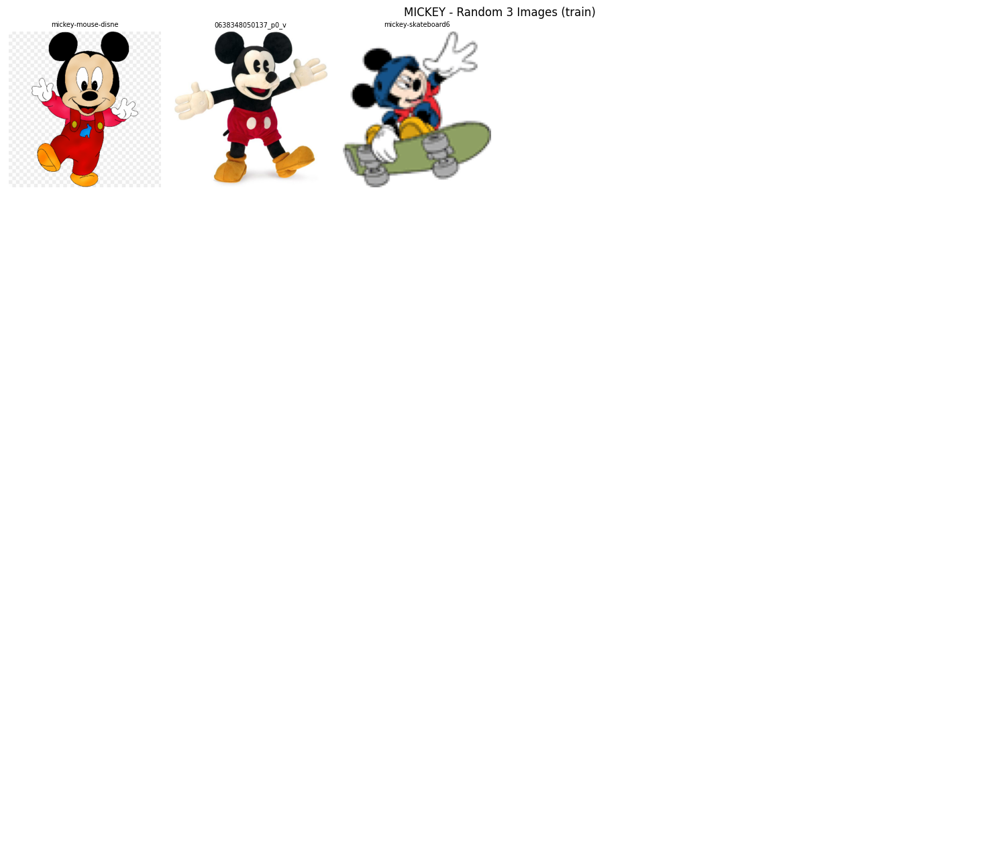

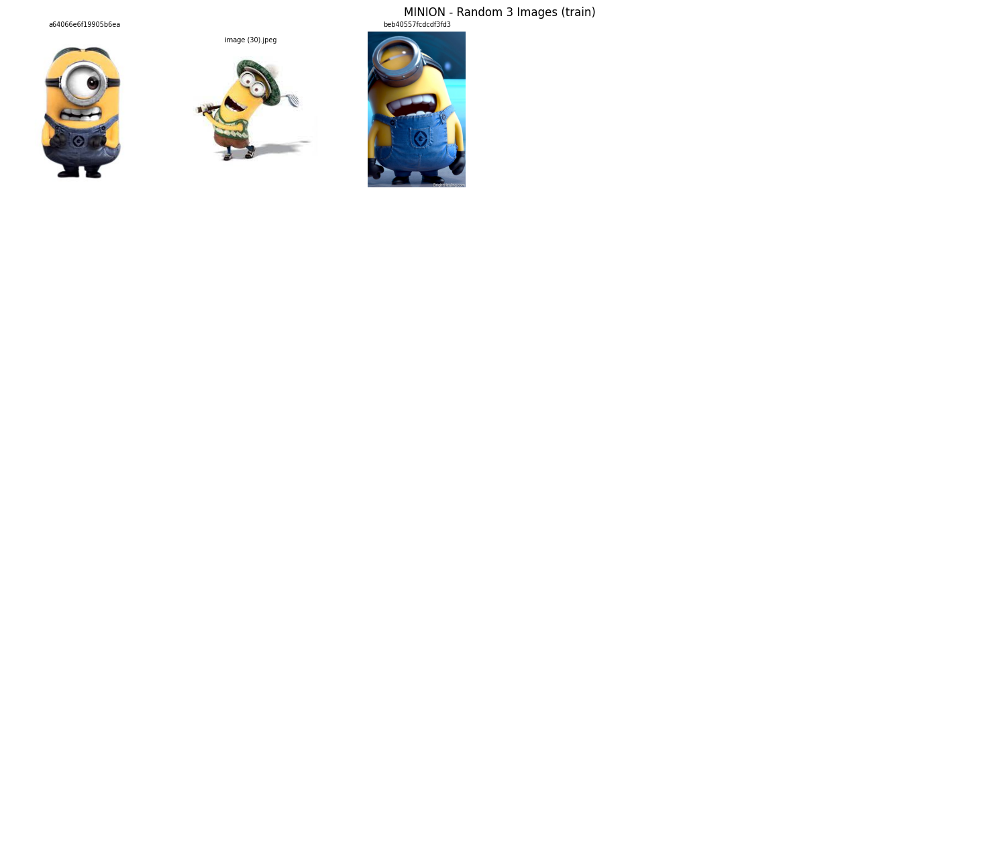

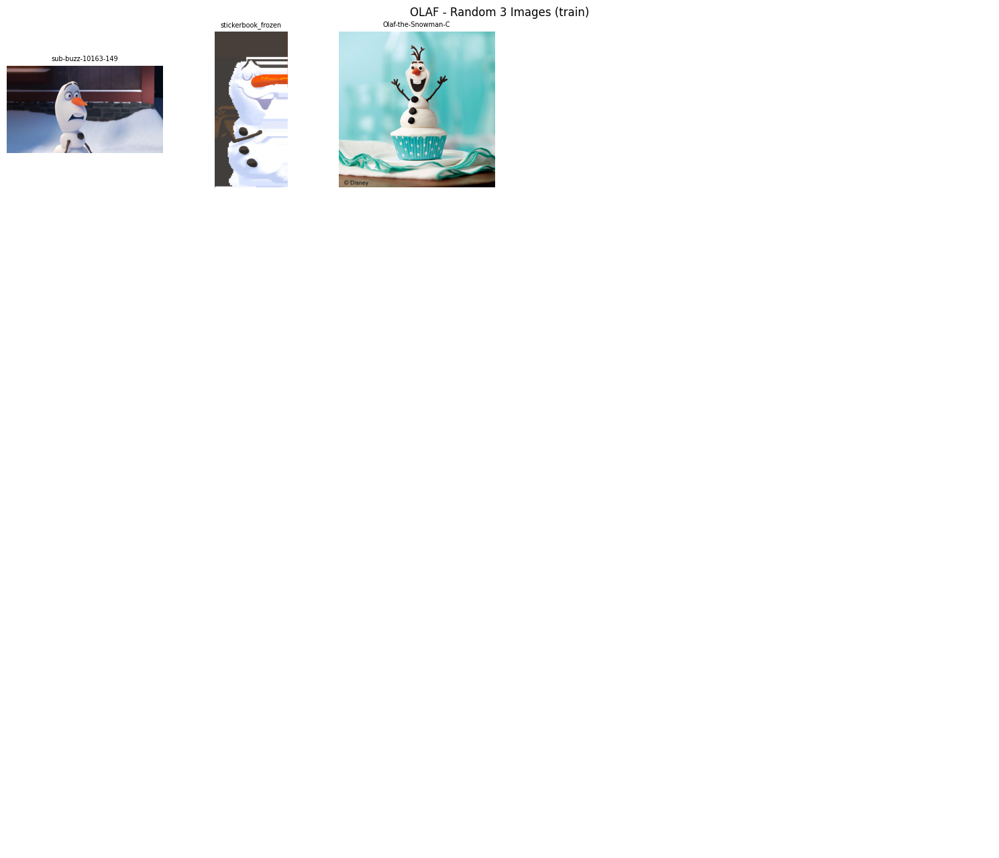

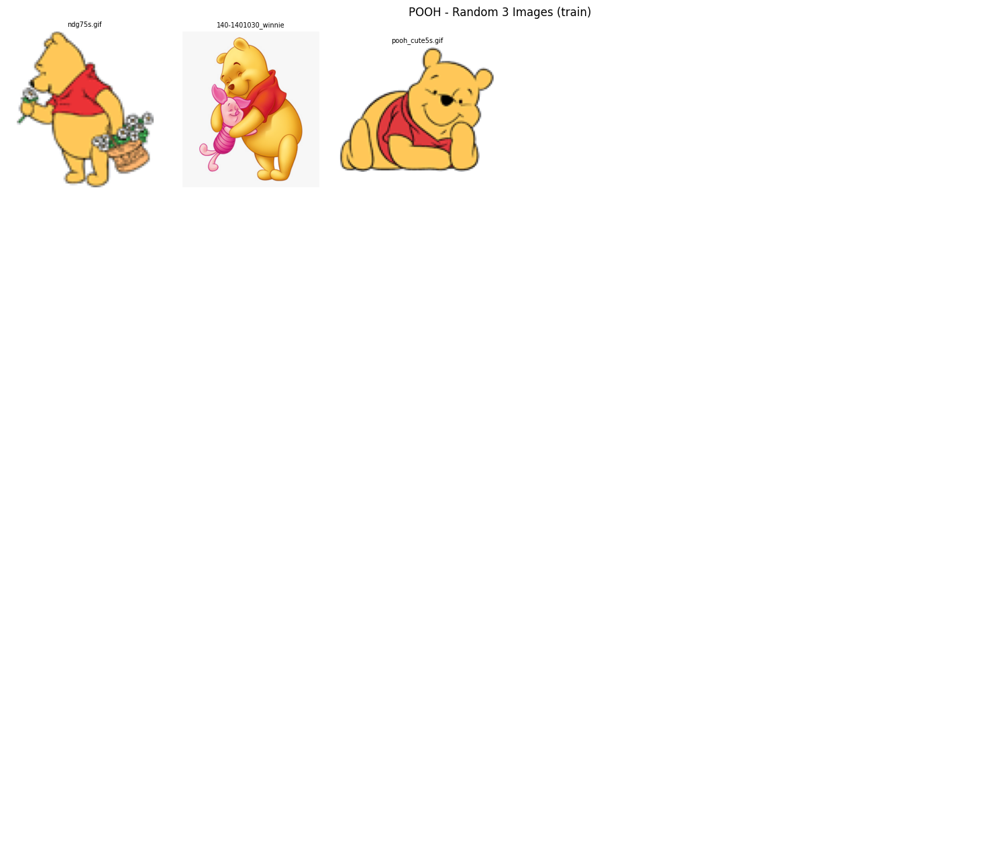

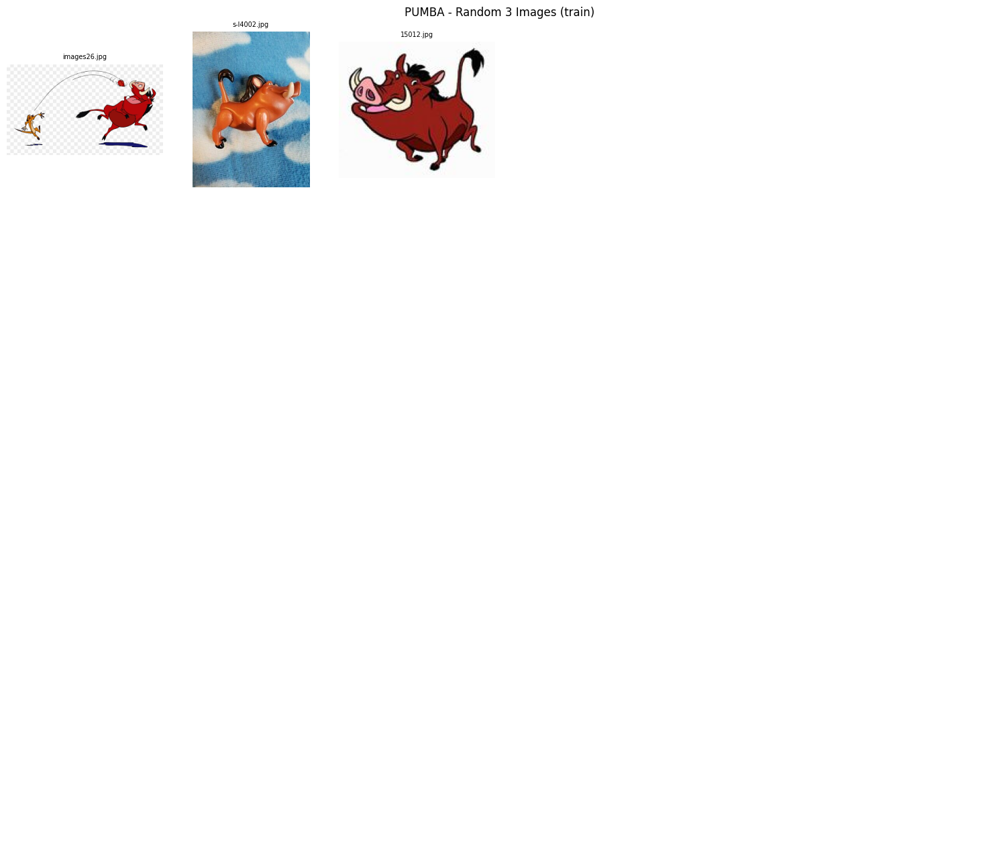

In [21]:
def generate_class_samples(
    metadata,
    split="train",
    samples_per_class=30
):
    """
    display a eandom sample fo images for every class
    uses valid and recoverable images only here
    """

    valid_data = metadata[
        (metadata["split"] == split) &
        (metadata["status"].isin(
            ["valid", "truncated_recoverable"]
        ))
    ]
    for class_name in CLASSES:
        class_data = valid_data[
            valid_data["class"] == class_name
        ]
        n_samples = min(
            samples_per_class,
            len(class_data)
        )
        sampled = class_data.sample(
            n=n_samples,
            random_state=SEED
        )
        fig, axes = plt.subplots(
            5, 6,
            figsize=(15, 13)
        )
        axes = axes.flatten()
        for ax in axes:
            ax.axis("off")
        for i, (_, row) in enumerate(sampled.iterrows()):
            with Image.open(row["path"]) as img:
                img.seek(0)
                ax = axes[i]
                ax.imshow(img.convert("RGB"))
                ax.set_title(
                    row["filename"][:18],
                    fontsize=7
                )
        plt.suptitle(
            f"{class_name.upper()} - Random {n_samples} Images ({split})"
        )
        plt.tight_layout()
        plt.show()

generate_class_samples(
    decode_df,
    split="train",
    samples_per_class=3
)

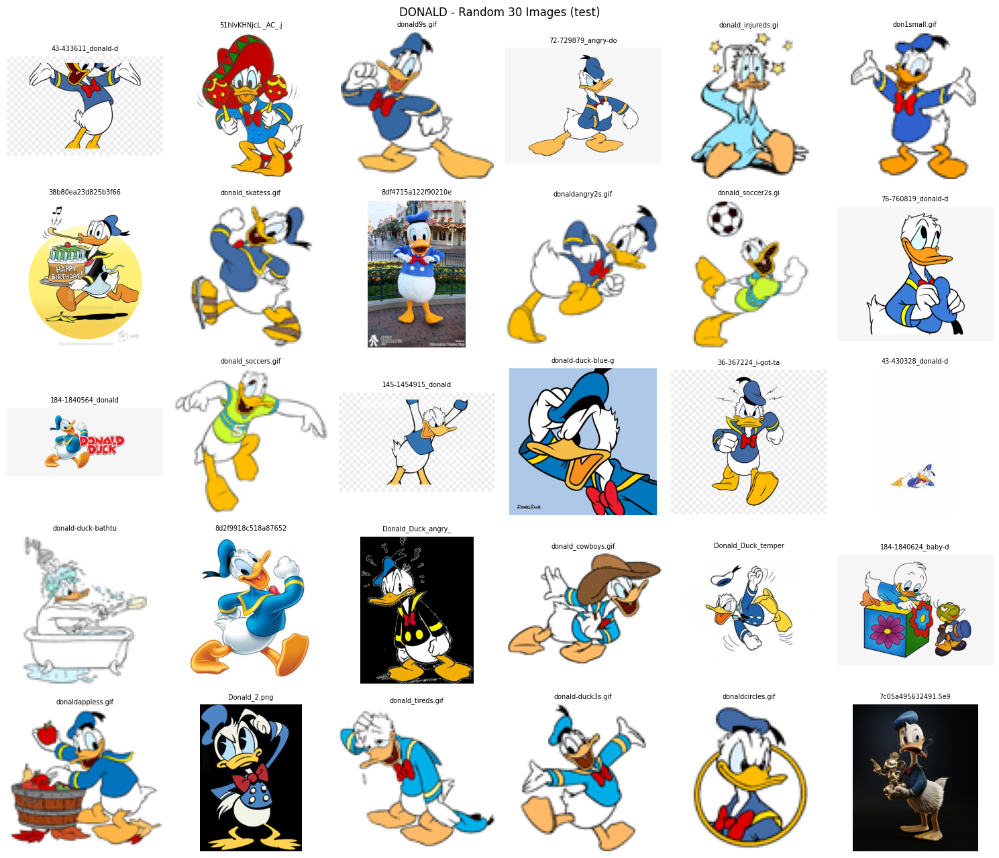

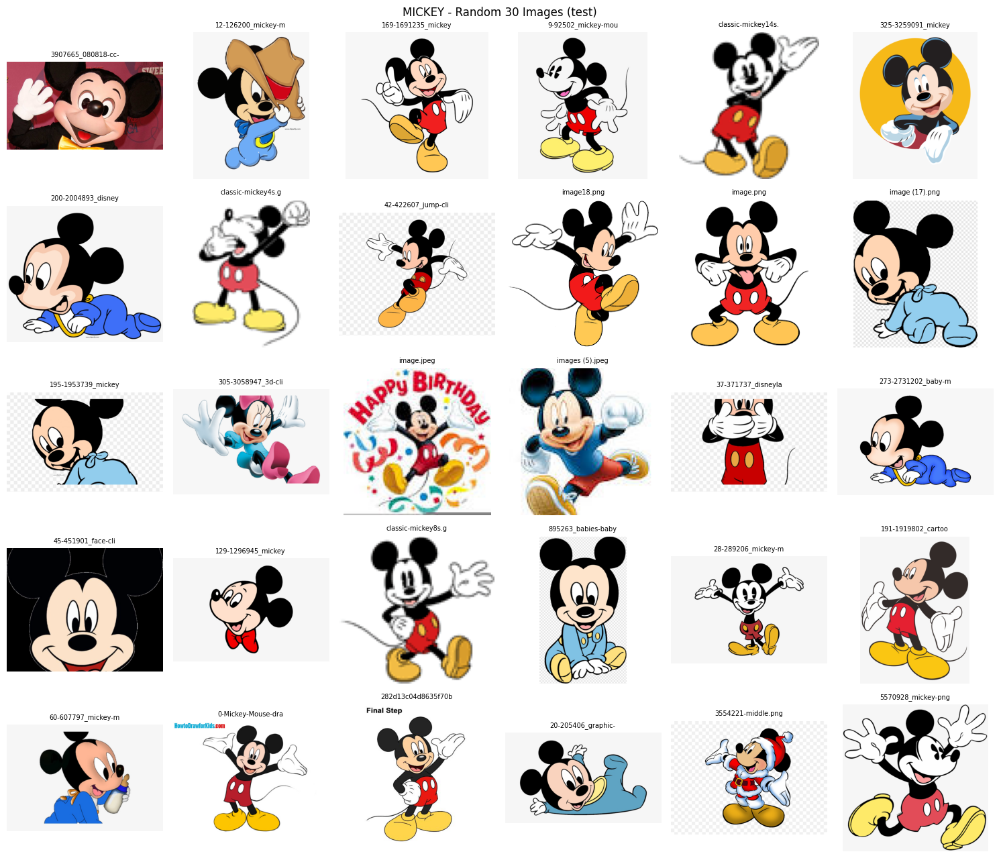

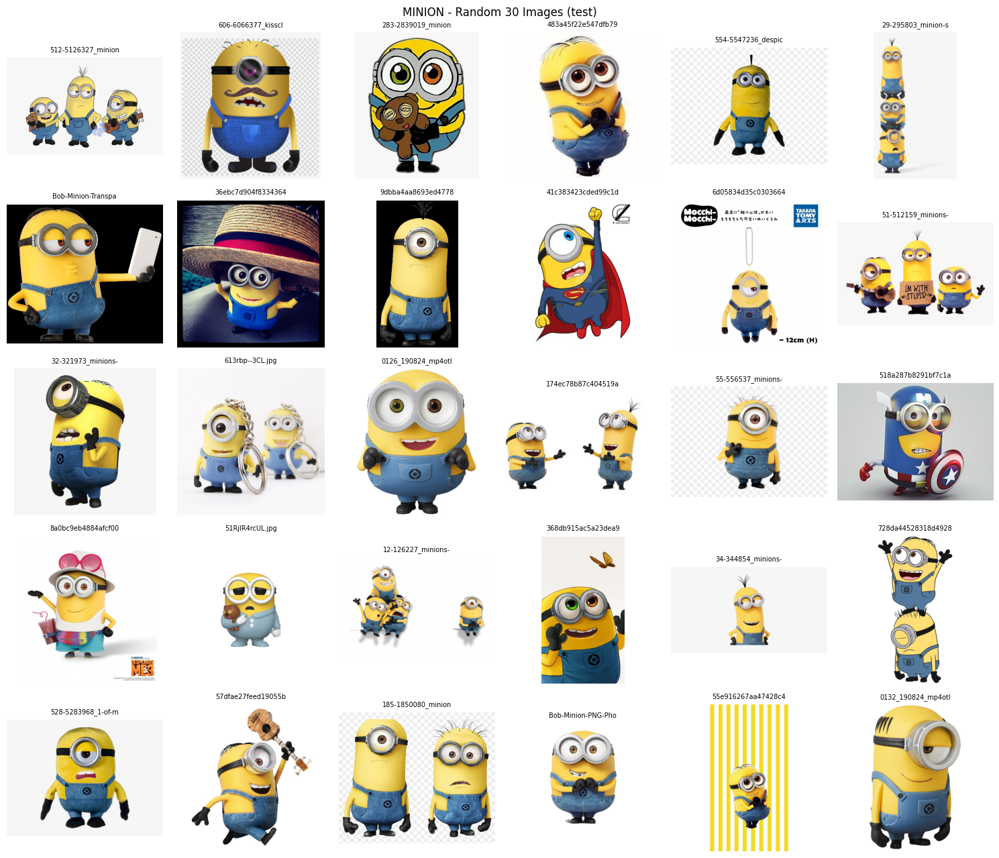

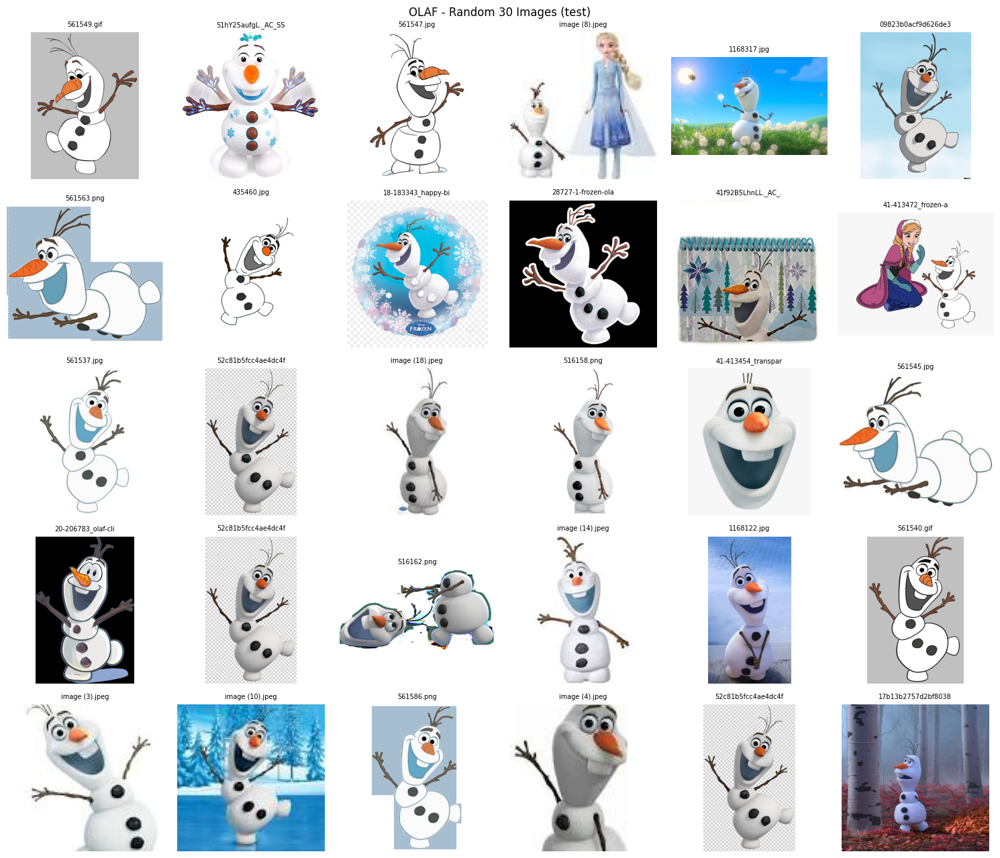

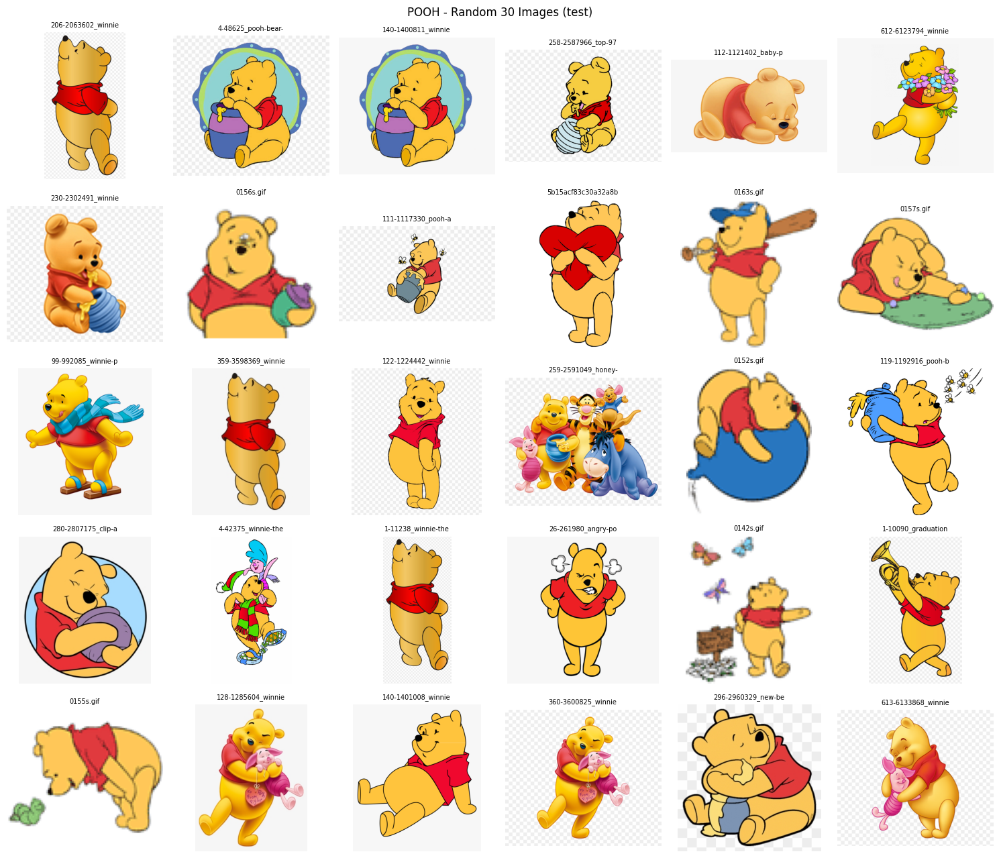

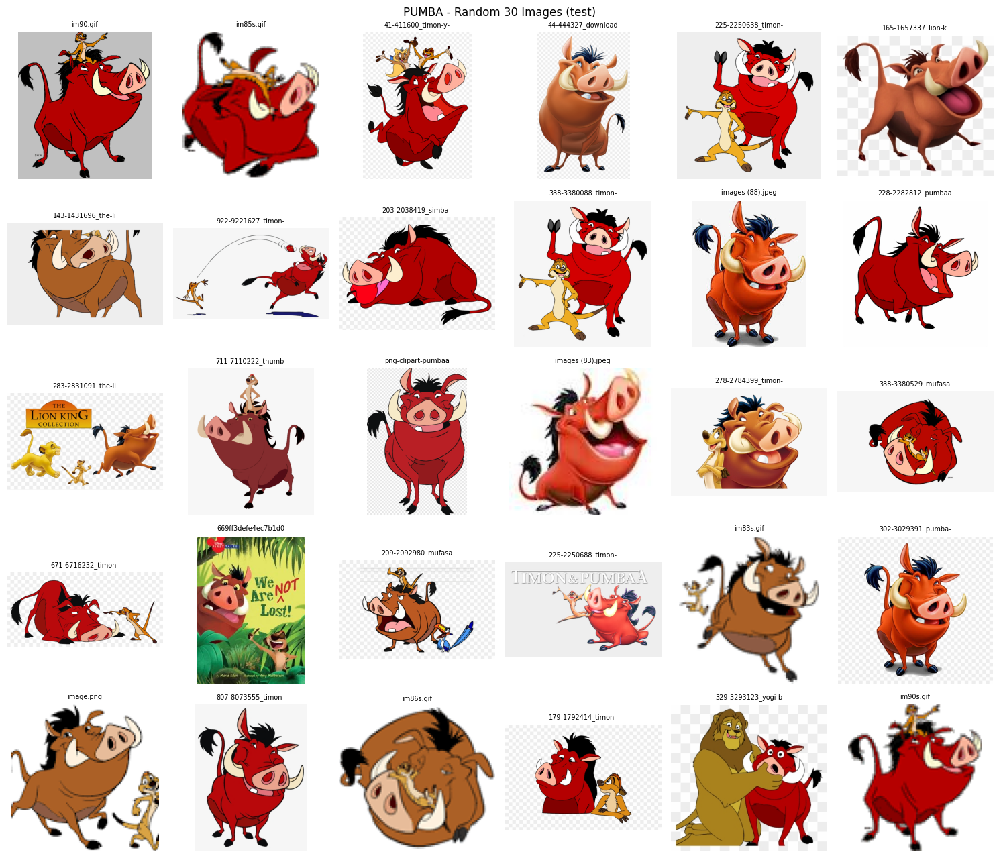

In [22]:
generate_class_samples(
    decode_df,
    split="test",
    samples_per_class=30
)

In [23]:
# create a manual review template from sampled images
def create_manual_review_template(
    metadata,
    split="train",
    samples_per_class=30
):
    """create a csv template for manual image inspection."""
    valid_data = metadata[
        (metadata["split"] == split) &
        (metadata["status"].isin(
            ["valid", "truncated_recoverable"]
        ))
    ]
    samples = []
    for class_name in CLASSES:
        class_data = valid_data[
            valid_data["class"] == class_name
        ]
        sampled = class_data.sample(
            n=min(samples_per_class, len(class_data)),
            random_state=SEED
        )
        for _, row in sampled.iterrows():
            samples.append({
                "path": row["path"],
                "split": split,
                "original_class": class_name,
                "decision": "keep",
                "correct_class": class_name,
                "multi_character": False,
                "watermark": False,
                "small_character": False,
                "comments": ""
            })
    review_df = pd.DataFrame(samples)
    output_path = (
        AUDIT_DIR / f"manual_review_{split}.csv"
    )
    review_df.to_csv(output_path, index=False)
    return review_df

train_review = create_manual_review_template(decode_df, "train", 30)
test_review = create_manual_review_template(decode_df, "test", 30)

print("Training review samples:", len(train_review))
print("Testing review samples:", len(test_review))
print("Review files saved in:", AUDIT_DIR)

Training review samples: 180
Testing review samples: 180
Review files saved in: /content/audit_results


In [24]:
def generate_audit_summary(auditor, hash_data, near_duplicates):
    """generate a preliminary before-cleaning audit summary."""
    inventory = auditor.inventory
    readability = auditor.decode_results
    summary = {
        "Total files": len(inventory),
        "Valid images": int(
            readability["status"].isin(
                ["valid", "truncated_recoverable"]
            ).sum()
        ),
        "Strictly readable images": int(
            (readability["status"] == "valid").sum()
        ),
        "Recoverable truncated images": int(
            (readability["status"] == "truncated_recoverable").sum()
        ),
        "Corrupted files": int(
            (readability["status"] == "corrupted").sum()
        ),
        "Non-image files": int(
            (readability["status"] == "not_image").sum()
        ),
        "Files hashed": len(hash_data),
        "Near-duplicate candidate pairs": len(near_duplicates)
    }

    summary_df = pd.DataFrame(summary.items(),columns=["Metric", "Value"])
    display(summary_df)
    summary_df.to_csv(AUDIT_DIR / "preliminary_audit_summary.csv",index=False)
    return summary_df

preliminary_summary = generate_audit_summary(
    auditor,
    hash_df,
    near_duplicates
)
print("\nAudit reports saved at:", AUDIT_DIR)

,Metric,Value
0,Total files,4667
1,Valid images,4667
2,Strictly readable images,4666
3,Recoverable truncated images,1
4,Corrupted files,0
5,Non-image files,0
6,Files hashed,4666
7,Near-duplicate candidate pairs,310



Audit reports saved at: /content/audit_results


In [25]:
# files that passed the readability check
valid_statuses = [
    "valid",
    "truncated_recoverable"
]

valid_files = decode_df[
    decode_df["status"].isin(valid_statuses)
].copy()

# Exact duplicate handling:
# Keep one copy of each SHA256 hash.
# Prefer the training copy if the duplicate occurs across splits.

hash_lookup = hash_df.set_index("path")["sha256"].to_dict()

valid_files["sha256"] = valid_files["path"].map(hash_lookup)

valid_files["split_priority"] = (
    valid_files["split"].map({"train": 0, "test": 1})
)

valid_files = valid_files.sort_values(
    ["split_priority", "path"]
)

exact_duplicate_paths = set(
    valid_files[
        valid_files.duplicated("sha256", keep="first")
    ]["path"]
)

print("Valid images:", len(valid_files))
print("Exact duplicate copies to remove:",
      len(exact_duplicate_paths))

# Remove exact duplicates
clean_candidates = valid_files[
    ~valid_files["path"].isin(exact_duplicate_paths)
].copy()

# Remove cross-split near-duplicate candidates from test.
# Training images are preferred.
near_duplicate_test_paths = set(
    near_duplicates["test_path"].unique()
) if len(near_duplicates) else set()

clean_candidates = clean_candidates[
    ~clean_candidates["path"].isin(
        near_duplicate_test_paths
    )
].copy()

print("Near-duplicate test images removed:",
      len(near_duplicate_test_paths))

print("Images remaining:", len(clean_candidates))


Valid images: 4667
Exact duplicate copies to remove: 149
Near-duplicate test images removed: 170
Images remaining: 4372


In [26]:
def normalise_and_save_image(source_path, destination_path):
    """
    Convert an image to RGB and save it.

    Animated GIFs use their first frame.
    Transparent images are composited onto white.
    """

    with Image.open(source_path) as img:

        # Use first frame for GIFs and other animated images
        img.seek(0)

        # Convert to RGBA to handle transparency
        rgba = img.convert("RGBA")

        # Composite onto white background
        background = Image.new(
            "RGBA",
            rgba.size,
            (255, 255, 255, 255)
        )

        background.alpha_composite(rgba)

        # Convert to RGB
        rgb_image = background.convert("RGB")

        # Save as JPEG
        rgb_image.save(
            destination_path,
            format="JPEG",
            quality=95
        )


# Create cleaned dataset
for split in SPLITS:
    for class_name in CLASSES:
        (CLEANED_DIR / split / class_name).mkdir(
            parents=True,
            exist_ok=True
        )


cleaning_errors = []

for _, row in tqdm(
    clean_candidates.iterrows(),
    total=len(clean_candidates),
    desc="Creating cleaned dataset"
):

    source = Path(row["path"])

    destination = (
        CLEANED_DIR
        / row["split"]
        / row["class"]
        / f"{source.stem}.jpg"
    )

    # Avoid filename collisions
    if destination.exists():
        destination = destination.with_name(
            f"{source.stem}_{hashlib.md5(str(source).encode()).hexdigest()[:8]}.jpg"
        )

    try:
        normalise_and_save_image(
            source,
            destination
        )

    except Exception as e:
        cleaning_errors.append({
            "source": str(source),
            "error": str(e)
        })


print("Cleaning completed!")
print("Cleaning errors:", len(cleaning_errors))
print("Cleaned dataset:", CLEANED_DIR)

if cleaning_errors:
    display(pd.DataFrame(cleaning_errors).head(20))

Creating cleaned dataset:   0%|          | 0/4372 [00:00<?, ?it/s]

Cleaning completed!
Cleaning errors: 1
Cleaned dataset: /content/disney_cleaned


,source,error
0,/content/disney_dataset/cartoon/train/donald/h...,image file is truncated (5 bytes not processed)


In [27]:
# Count final images
final_records = []

for split in SPLITS:
    for class_name in CLASSES:

        folder = CLEANED_DIR / split / class_name

        count = len(list(folder.glob("*.jpg")))

        final_records.append({
            "split": split,
            "class": class_name,
            "final_images": count
        })

final_counts_df = pd.DataFrame(final_records)

print("Final cleaned class distribution:")
display(
    final_counts_df.pivot(
        index="class",
        columns="split",
        values="final_images"
    )
)

# Overall summary
before_count = len(inventory_df)
valid_count = len(valid_files)
exact_removed = len(exact_duplicate_paths)
near_removed = len(near_duplicate_test_paths)

after_count = int(final_counts_df["final_images"].sum())

before_after_summary = pd.DataFrame({
    "Metric": [
        "Original files",
        "Valid/recoverable images",
        "Exact duplicate copies removed",
        "Near-duplicate test candidates removed",
        "Cleaning errors",
        "Final cleaned images"
    ],
    "Count": [
        before_count,
        valid_count,
        exact_removed,
        near_removed,
        len(cleaning_errors),
        after_count
    ]
})

display(before_after_summary)

before_after_summary.to_csv(
    AUDIT_DIR / "before_after_summary.csv",
    index=False
)

final_counts_df.to_csv(
    AUDIT_DIR / "final_class_distribution.csv",
    index=False
)


Final cleaned class distribution:


split,test,train
class,,
donald,86,633
mickey,69,715
minion,51,679
olaf,56,590
pooh,50,738
pumba,29,675


,Metric,Count
0,Original files,4667
1,Valid/recoverable images,4667
2,Exact duplicate copies removed,149
3,Near-duplicate test candidates removed,170
4,Cleaning errors,1
5,Final cleaned images,4371


In [28]:
from sklearn.model_selection import train_test_split
from collections import Counter

def load_cartoon_data(
    cleaned_dir,
    classes,
    validation_size=0.15,
    random_state=42
):
    """
    Load cleaned cartoon dataset and create stratified splits.

    The provided test set is retained unchanged.
    Validation is sampled from the training set.
    """

    cleaned_dir = Path(cleaned_dir)

    paths = []
    labels = []

    # Collect cleaned training images
    for label, class_name in enumerate(classes):
        class_dir = cleaned_dir / "train" / class_name
        for image_path in sorted(class_dir.glob("*.jpg")):
            paths.append(str(image_path))
            labels.append(label)

    paths = np.array(paths)
    labels = np.array(labels)

    # Stratified train-validation split
    train_paths, val_paths, train_labels, val_labels = (
        train_test_split(
            paths,
            labels,
            test_size=validation_size,
            stratify=labels,
            random_state=random_state
        )
    )

    # Load provided test set without splitting
    test_paths = []
    test_labels = []

    for label, class_name in enumerate(classes):

        class_dir = cleaned_dir / "test" / class_name

        for image_path in sorted(class_dir.glob("*.jpg")):
            test_paths.append(str(image_path))
            test_labels.append(label)

    test_paths = np.array(test_paths)
    test_labels = np.array(test_labels)

    return {
        "train": (train_paths, train_labels),
        "validation": (val_paths, val_labels),
        "test": (
            np.array(test_paths),
            np.array(test_labels)
        )
    }


data_splits = load_cartoon_data(
    cleaned_dir=CLEANED_DIR,
    classes=CLASSES,
    validation_size=0.15,
    random_state=SEED
)

print("Dataset splitting completed!")

Dataset splitting completed!


In [29]:
def print_split_statistics(data_splits, classes):
    """Print dataset sizes and class distributions."""

    rows = []

    for split_name, (paths, labels) in data_splits.items():

        counts = Counter(labels)

        print(f"\n{split_name.upper()} SET")
        print("Total images:", len(paths))

        for label, class_name in enumerate(classes):

            count = counts[label]

            print(f"{class_name}: {count}")

            rows.append({
                "split": split_name,
                "class": class_name,
                "count": count
            })

    return pd.DataFrame(rows)


split_statistics = print_split_statistics(
    data_splits,
    CLASSES
)

display(
    split_statistics.pivot(
        index="class",
        columns="split",
        values="count"
    )
)


TRAIN SET
Total images: 3425
donald: 538
mickey: 608
minion: 577
olaf: 501
pooh: 627
pumba: 574

VALIDATION SET
Total images: 605
donald: 95
mickey: 107
minion: 102
olaf: 89
pooh: 111
pumba: 101

TEST SET
Total images: 341
donald: 86
mickey: 69
minion: 51
olaf: 56
pooh: 50
pumba: 29


split,test,train,validation
class,,,
donald,86,538,95
mickey,69,608,107
minion,51,577,102
olaf,56,501,89
pooh,50,627,111
pumba,29,574,101


In [30]:
def verify_split_independence(data_splits):
    """Verify that train, validation and test paths do not overlap."""

    train_paths = set(data_splits["train"][0])
    val_paths = set(data_splits["validation"][0])
    test_paths = set(data_splits["test"][0])

    train_val_overlap = train_paths.intersection(val_paths)
    train_test_overlap = train_paths.intersection(test_paths)
    val_test_overlap = val_paths.intersection(test_paths)

    print("Train-Validation overlap:", len(train_val_overlap))
    print("Train-Test overlap:", len(train_test_overlap))
    print("Validation-Test overlap:", len(val_test_overlap))

    assert len(train_val_overlap) == 0
    assert len(train_test_overlap) == 0
    assert len(val_test_overlap) == 0

    print("\nPASS: No path overlap between the three splits.")

verify_split_independence(data_splits)

Train-Validation overlap: 0
Train-Test overlap: 0
Validation-Test overlap: 0

PASS: No path overlap between the three splits.


In [31]:
from PIL import Image, ImageOps

def resize_with_padding(image, target_size=(64,64)):
  """
  resize the imges while preserving their aspect ratios"""

  image = image.convert("RGB")
  target_width,target_height = target_size

  #Resize while preserving aspect ratio
  resized = ImageOps.contain(
      image,
      target_size,
      method = Image.Resampling.LANCZOS
  )

  canvas = Image.new("RGB",target_size,(255,255,255))

  x_offset = (target_width - resized.width)//2
  y_offset = (target_height - resized.height)//2

  canvas.paste(resized,(x_offset,y_offset))

  return canvas

In [34]:
from torch.utils.data import Dataset
from torchvision import transforms

class CartoonDataset(Dataset):
  """
  custom torch dataset for cartoon characters classification
  images are resized and cached in mem during initialisation
  """
  def __init__(
      self,
      image_paths,
      labels,
      image_size=(64,64),
      transform = None
  ):
    self.image_paths = list(image_paths)
    self.labels = torch.tensor(labels,dtype=torch.long)
    self.transform=transform
    self.images=[]

    for image_path in tqdm(
        self.image_paths,
        desc="Caching images"
    ):
      with Image.open(image_path) as img:
        img.seek(0)
        resized = resize_with_padding(img,target_size=image_size)
        self.images.append(resized.copy())

  def __len__(self):
    return len(self.labels)

  def __getitem__(self,index):
    """return trandformed image and corresponding label"""
    image = self.images[index].copy()
    label = self.labels[index]
    if self.transform is not None:
      image = self.transform(image)
    return image,label

In [35]:
#get split info
train_paths,train_labels = data_splits["train"]
val_paths,val_labels = data_splits["validation"]
test_paths,test_labels = data_splits["test"]

train_dataset_base = CartoonDataset(
    train_paths,
    train_labels,
    image_size=TARGET_SIZE
)
val_dataset_base = CartoonDataset(
    val_paths,
    val_labels,
    image_size=TARGET_SIZE
)
test_dataset_base = CartoonDataset(
    test_paths,
    test_labels,
    image_size=TARGET_SIZE
)

print("\nCached dataset size:")
print("Train:", len(train_dataset_base))
print("Validation:", len(val_dataset_base))
print("Test:", len(test_dataset_base))

Caching images:   0%|          | 0/3425 [00:00<?, ?it/s]

Caching images:   0%|          | 0/605 [00:00<?, ?it/s]

Caching images:   0%|          | 0/341 [00:00<?, ?it/s]


Cached dataset size:
Train: 3425
Validation: 605
Test: 341


In [36]:
to_tensor = transforms.ToTensor()
train_tensor_stack = torch.stack([
    to_tensor(image) for image in train_dataset_base.images
])
CHANNEL_MEAN = train_tensor_stack.mean(dim=(0,2,3))
CHANNEL_STD = train_tensor_stack.std(dim=(0,2,3),unbiased=False)

print("Training channel mean:", CHANNEL_MEAN)
print("Training channel std:", CHANNEL_STD)

print("\nRGB Mean:")
print(CHANNEL_MEAN.tolist())

print("\nRGB Standard Deviation:")
print(CHANNEL_STD.tolist())

del train_tensor_stack

Training channel mean: tensor([0.8118, 0.7805, 0.7443])
Training channel std: tensor([0.2846, 0.2988, 0.3369])

RGB Mean:
[0.8117658495903015, 0.7804619669914246, 0.7443177700042725]

RGB Standard Deviation:
[0.2845592796802521, 0.2988460063934326, 0.33692267537117004]


In [37]:
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10,fill=(255,255,255)),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.15,
        hue=0.15
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=CHANNEL_MEAN.tolist(),
        std=CHANNEL_STD.tolist()
    )
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=CHANNEL_MEAN.tolist(),
        std=CHANNEL_STD.tolist()
    )
])

print("Train and evaluation trandformstions defined")

Train and evaluation trandformstions defined


In [38]:
# training dataset with augumentation
train_dataset = CartoonDataset(
    train_paths,
    train_labels,
    image_size=TARGET_SIZE,
    transform=train_transform
)
#validation datadet without augumentation
val_dataset = CartoonDataset(
    val_paths,
    val_labels,
    image_size = TARGET_SIZE,
    transform = eval_transform
)
#test dataset without augumentation
test_dataset = CartoonDataset(
    test_paths,
    test_labels,
    image_size = TARGET_SIZE,
    transform= eval_transform
)

print("final dataset created sucessfully")

Caching images:   0%|          | 0/3425 [00:00<?, ?it/s]

Caching images:   0%|          | 0/605 [00:00<?, ?it/s]

Caching images:   0%|          | 0/341 [00:00<?, ?it/s]

final dataset created sucessfully


In [41]:
from collections import Counter

train_class_counts = Counter(train_labels)
imbalance_df = pd.DataFrame([
    {
        "class": CLASSES[i],
        "count": train_class_counts[i]
    }
    for i in range(len(CLASSES))
])
display(imbalance_df)
imbalance_ratio=(
    imbalance_df["count"].max() / imbalance_df["count"].min()
)
print("Imbalance ratio:", round(imbalance_ratio,3))
USE_WEIGHTED_SAMPLER = imbalance_ratio >= 1.2
print("weighted sampler enabled:",USE_WEIGHTED_SAMPLER)

,class,count
0,donald,538
1,mickey,608
2,minion,577
3,olaf,501
4,pooh,627
5,pumba,574


Imbalance ratio: 1.251
weighted sampler enabled: True


In [44]:
import torch

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)
print("CUDA available:", torch.cuda.is_available())

Device: cuda
CUDA available: True


In [45]:
from torch.utils.data import DataLoader,WeightedRandomSampler

BATCH_SIZE=64
NUM_WORKERS=2

if USE_WEIGHTED_SAMPLER:
  class_weight = {
      class_id: 1.0/train_class_counts[class_id]
      for class_id in range(len(CLASSES))
  }

  sample_weights = [
      class_weight[int(label)]
      for label in train_labels
  ]

  train_sampler = WeightedRandomSampler(
      weights=sample_weights,
      num_samples=len(sample_weights),
      replacement=True
  )

  train_loader = DataLoader(
      train_dataset,
      batch_size=BATCH_SIZE,
      sampler=train_sampler,
      num_workers=NUM_WORKERS,
      pin_memory=(DEVICE.type=="cuda")
  )

else:
  train_loader = DataLoader(
      train_dataset,
      batch_size=BATCH_SIZE,
      shuffle=True,
      num_workers=NUM_WORKERS,
      pin_memory=(DEVICE.type=="cuda")
  )


val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type=="cuda")
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type=="cuda")
)

print("DataLoaders Created")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:",len(test_loader))

DataLoaders Created
Training batches: 54
Validation batches: 10
Testing batches: 6


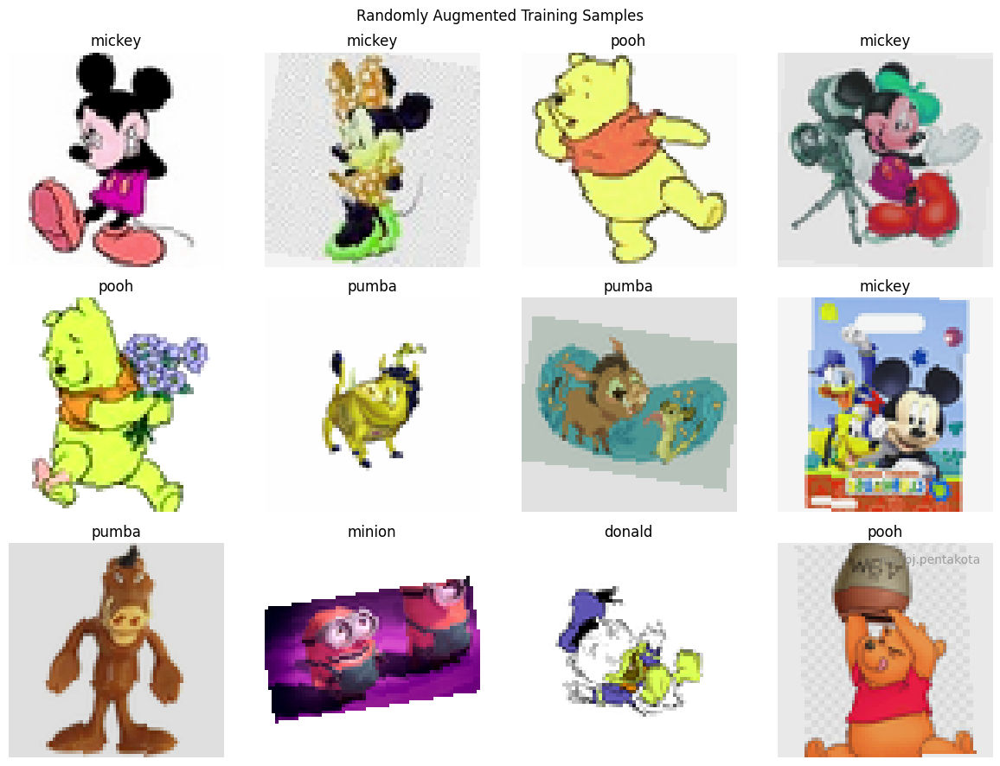

In [46]:
def denormalize_image(image, mean, std):
    """reverse channel-wise image normalisation"""

    mean = torch.tensor(mean).view(3, 1, 1)
    std = torch.tensor(std).view(3, 1, 1)
    return image * std + mean

def plot_augmented_samples(
    dataset,
    classes,
    num_samples=12
):
    """display augmented images from the training dataset"""

    indices = np.random.choice(
        len(dataset),
        size=min(num_samples, len(dataset)),
        replace=False
    )
    cols = 4
    rows = int(np.ceil(len(indices) / cols))
    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(12, 3 * rows)
    )
    axes = np.array(axes).flatten()
    for ax in axes:
        ax.axis("off")

    for i, index in enumerate(indices):
        image, label = dataset[index]
        image = denormalize_image(
            image,
            CHANNEL_MEAN.tolist(),
            CHANNEL_STD.tolist()
        )

        image = image.clamp(0, 1)
        axes[i].imshow(
            image.permute(1, 2, 0).numpy()
        )
        axes[i].set_title(
            classes[label.item()]
        )
        axes[i].axis("off")

    plt.suptitle("Randomly Augmented Training Samples")

    plt.text(
        0.95, 0.95, EMAIL_USERNAME,
        ha="right", va="top",
        transform=plt.gca().transAxes,
        fontsize=10, color="gray", alpha=0.7
    )
    plt.tight_layout()
    plt.savefig(
        AUDIT_DIR / "augmented_samples.png",
        dpi=300
    )
    plt.show()
plot_augmented_samples(
    train_dataset,
    CLASSES,
    num_samples=12
)

In [47]:
images, labels = next(iter(train_loader))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)
print("Image range:", images.min().item(),"to", images.max().item())
print("Unique labels:", torch.unique(labels))

assert images.shape[1:] == (3, 64, 64)
assert labels.ndim == 1
assert len(images) == len(labels)

print("\nPASS: Training batch verification successful.")

Image batch shape: torch.Size([64, 3, 64, 64])
Label batch shape: torch.Size([64])
Image dtype: torch.float32
Label dtype: torch.int64
Image range: -2.852712631225586 to 0.7588751316070557
Unique labels: tensor([0, 1, 2, 3, 4, 5])

PASS: Training batch verification successful.


In [48]:
import json

pipeline_config = {
    "seed": SEED,
    "classes": CLASSES,
    "image_size": list(TARGET_SIZE),
    "validation_size": 0.15,
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "normalization_mean": CHANNEL_MEAN.tolist(),
    "normalization_std": CHANNEL_STD.tolist(),
    "weighted_sampler": USE_WEIGHTED_SAMPLER,
    "augmentation": [
        "RandomHorizontalFlip",
        "RandomRotation",
        "ColorJitter"
    ],
    "resize_policy": "Aspect-ratio preserving resize with white padding"
}

with open(
    AUDIT_DIR / "data_pipeline_config.json",
    "w"
) as f:
    json.dump(pipeline_config, f, indent=4)

print("Data pipeline configuration saved!")

Data pipeline configuration saved!


In [50]:
# CNN Architecture

import torch
import torch.nn as nn
import torch.nn.functional as F

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
import copy
import time
import json
import random

def set_seed(seed=36):
  random.seed(seed)
  np.random.seed(seed)
  torch.manual_seed(seed)
  torch.cuda.manual_seed_all(seed)
  torch.backends.cudnn.deterministic=True
  torch.backends.cudnn.benchmark=False

SEED=36
set_seed(SEED)

INPUT_CHANNELS=3
NUM_CLASSES=6
IMAGE_SIZE=64
FILTERS = [32,64,128]
DROPOUT_RATE=0.3

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CHECKPOINT_DIR = Path("/content/chackpoints")
CHECKPOINT_DIR.mkdir(parents=True,exist_ok=True)

print("Device:",DEVICE)
print("Number of classes:", NUM_CLASSES)
print("Filters:", FILTERS)

Device: cuda
Number of classes: 6
Filters: [32, 64, 128]


In [51]:
class ConvBlock(nn.Module):
  """
  a convolutional block consisting of
  conv2D --> BatchNorm --> ReLU --> MaxPool2D
  """
  def __init__(self,in_channels,out_channels):
    super().__init__()
    self.conv=nn.Conv2d(
        in_channels=in_channels,
        out_channels=out_channels,
        kernel_size=3,
        stride=1,
        padding=1,
        bias=False
    )
    self.bn = nn.BatchNorm2d(out_channels)
    self.relu = nn.ReLU(inplace=True)
    self.pool = nn.MaxPool2d(kernel_size=2,stride=2)

  def forward(self,x):
    x=self.conv(x)
    x=self.bn(x)
    x=self.relu(x)
    x=self.pool(x)
    return x

In [52]:
class CartoonCNN(nn.Module):
  """
  cnn architecture
  input
  --> convblock 1 (32 filters)
  --> convblock 2 (64 filters)
  --> convblock 3 (128 filters)
  --> global average pooling
  --> dropout
  --> fc
  """
  def __init__(
      self,
      num_classes=6,
      input_channels=3,
      filters=(32,64,128),
      dropout_rate=0.3
  ):
    super().__init__()
    self.block1=ConvBlock(input_channels,filters[0])
    self.block2=ConvBlock(filters[0],filters[1])
    self.block3=ConvBlock(filters[1],filters[2])
    self.global_pool=nn.AdaptiveAvgPool2d(output_size=1)
    self.dropout=nn.Dropout2d(p=dropout_rate)
    self.classifier=nn.Linear(filters[2],num_classes)
    self.initialize_weights()

  def initialize_weights(self):
    for module in self.modules():
      if isinstance(module,nn.Conv2d):
        nn.init.kaiming_normal_(
            module.weight,
            mode="fan_out",
            nonlinearity="relu"
        )
        if module.bias is not None:
          nn.init.zeros_(module.bias)
      elif isinstance(module,nn.Linear):
        nn.init.kaiming_normal_(
            module.weight,
            mode="fan_in",
            nonlinearity="relu"
        )
        nn.init.zeros_(module.bias)

  def forward(self, x, return_features=False):
    """
    forward pass through the complete cnn model
    """
    features={}
    x = self.block1(x)
    features["block1"]=x
    x = self.block2(x)
    features["block2"]=x
    x = self.block3(x)
    features["block3"]=x

    x = self.global_pool(x)
    x = torch.flatten(x, start_dim=1)
    x = self.dropout(x)
    logits = self.classifier(x)

    if return_features:
      return logits, features

    return logits

In [53]:
model = CartoonCNN(
    num_classes=NUM_CLASSES,
    input_channels=INPUT_CHANNELS,
    filters=FILTERS,
    dropout_rate=DROPOUT_RATE
).to(DEVICE)

dummy_input = torch.randn(4, 3, 64, 64).to(DEVICE)
model.eval()
with torch.no_grad():
    logits, feature_maps = model(
        dummy_input,
        return_features=True
    )

print("Input shape:", dummy_input.shape)
print("Output logits shape:", logits.shape)

print("\nIntermediate feature map shapes:")

for name, feature in feature_maps.items():
    print(name, ":", feature.shape)

assert logits.shape == (4, 6)
assert feature_maps["block1"].shape == (4, 32, 32, 32)
assert feature_maps["block2"].shape == (4, 64, 16, 16)
assert feature_maps["block3"].shape == (4, 128, 8, 8)

print("\nPASS: Architecture verification successful.")

Input shape: torch.Size([4, 3, 64, 64])
Output logits shape: torch.Size([4, 6])

Intermediate feature map shapes:
block1 : torch.Size([4, 32, 32, 32])
block2 : torch.Size([4, 64, 16, 16])
block3 : torch.Size([4, 128, 8, 8])

PASS: Architecture verification successful.


In [54]:
def count_parameters(module):
    """count trainable parameters in a module"""

    return sum(
        p.numel()
        for p in module.parameters()
        if p.requires_grad
    )

def generate_architecture_summary(model):
    """generate a table of architecture shapes and parameter counts"""
    layer_data = [
        {
            "Layer": "Input",
            "Output Shape": "(3, 64, 64)",
            "Parameters": 0
        },
        {
            "Layer": "Conv Block 1",
            "Output Shape": "(32, 32, 32)",
            "Parameters": count_parameters(model.block1)
        },
        {
            "Layer": "Conv Block 2",
            "Output Shape": "(64, 16, 16)",
            "Parameters": count_parameters(model.block2)
        },
        {
            "Layer": "Conv Block 3",
            "Output Shape": "(128, 8, 8)",
            "Parameters": count_parameters(model.block3)
        },
        {
            "Layer": "Global Average Pooling",
            "Output Shape": "(128, 1, 1)",
            "Parameters": count_parameters(model.global_pool)
        },
        {
            "Layer": "Dropout",
            "Output Shape": "(128)",
            "Parameters": count_parameters(model.dropout)
        },
        {
            "Layer": "Fully Connected",
            "Output Shape": "(6)",
            "Parameters": count_parameters(model.classifier)
        }
    ]
    summary_df = pd.DataFrame(layer_data)
    total_params = count_parameters(model)
    total_row = pd.DataFrame([{
        "Layer": "TOTAL",
        "Output Shape": "-",
        "Parameters": total_params
    }])
    summary_df = pd.concat(
        [summary_df, total_row],
        ignore_index=True
    )
    return summary_df

architecture_summary = generate_architecture_summary(model)
display(architecture_summary)
total_parameters = count_parameters(model)
print(f"\nTotal trainable parameters: {total_parameters:,}")

,Layer,Output Shape,Parameters
0,Input,"(3, 64, 64)",0
1,Conv Block 1,"(32, 32, 32)",928
2,Conv Block 2,"(64, 16, 16)",18560
3,Conv Block 3,"(128, 8, 8)",73984
4,Global Average Pooling,"(128, 1, 1)",0
5,Dropout,(128),0
6,Fully Connected,(6),774
7,TOTAL,-,94246



Total trainable parameters: 94,246


In [55]:
def calculate_model_size(model):
  """estimate model parameter storage size"""
  parameter_size = sum(
      p.numel() * p.element_size()
      for p in model.parameters()
  )
  buffer_size = sum(
      b.numel() * b.element_size()
      for b in model.buffers()
  )
  total_size_mb = (parameter_size + buffer_size)/(1024**2)
  return total_size_mb

print(f"Model size: {calculate_model_size(model):.2f} MB")

Model size: 0.36 MB


In [56]:
class Trainer:
    """
    trainer class for our CartoonCNN
    """
    def __init__(
        self,
        model,
        train_loader,
        val_loader,
        optimizer_name="Adam",
        learning_rate=0.001,
        weight_decay=0.0001,
        momentum=0.9,
        patience=7,
        max_epochs=30,
        checkpoint_path="/content/checkpoints/best_model.pth",
        device=DEVICE
    ):
        self.model = model
        self.train_loader = train_loader
        self.val_loader = val_loader
        self.device = device
        self.model.to(self.device)
        self.criterion = nn.CrossEntropyLoss()
        self.learning_rate = learning_rate
        self.weight_decay = weight_decay

        if optimizer_name.lower() == "adam":
            self.optimizer = torch.optim.Adam(
                self.model.parameters(),
                lr=learning_rate,
                weight_decay=weight_decay
            )
        elif optimizer_name.lower() == "adamw":
            self.optimizer = torch.optim.AdamW(
                self.model.parameters(),
                lr=learning_rate,
                weight_decay=weight_decay
            )
        elif optimizer_name.lower() == "sgd":
            self.optimizer = torch.optim.SGD(
                self.model.parameters(),
                lr=learning_rate,
                momentum=momentum,
                weight_decay=weight_decay
            )
        else:
            raise ValueError(
                "Optimizer must be SGD, Adam or AdamW."
            )

        self.scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            self.optimizer,
            mode="max",
            factor=0.5,
            patience=3,
            min_lr=1e-6
        )

        self.patience = patience
        self.max_epochs = max_epochs
        self.checkpoint_path = Path(checkpoint_path)
        self.checkpoint_path.parent.mkdir(parents=True,exist_ok=True)
        self.history = {
            "train_loss": [],
            "val_loss": [],
            "train_accuracy": [],
            "val_accuracy": [],
            "learning_rate": []
        }
        self.best_val_accuracy = 0.0
        self.best_epoch = 0

    def run_epoch(self, loader, training=True):
        if training:
            self.model.train()
        else:
            self.model.eval()

        total_loss = 0.0
        correct = 0
        total = 0
        context = torch.enable_grad() if training else torch.no_grad()
        with context:
            for images, labels in loader:
                images = images.to(self.device,non_blocking=True)
                labels = labels.to(self.device,non_blocking=True)
                if training:
                    self.optimizer.zero_grad(set_to_none=True)

                logits = self.model(images)
                loss = self.criterion(logits,labels)
                if training:
                    loss.backward()
                    self.optimizer.step()

                batch_size = labels.size(0)
                total_loss += loss.item() * batch_size
                predictions = torch.argmax(logits,dim=1)
                correct += (predictions == labels).sum().item()
                total += batch_size

        average_loss = total_loss / total
        accuracy = correct / total
        return average_loss, accuracy

    def save_checkpoint(self, epoch, val_accuracy):
        checkpoint = {
            "epoch": epoch,
            "model_state_dict": self.model.state_dict(),
            "optimizer_state_dict": self.optimizer.state_dict(),
            "val_accuracy": val_accuracy
        }
        torch.save(checkpoint,self.checkpoint_path)

    def fit(self):
        epochs_without_improvement = 0
        for epoch in range(1, self.max_epochs + 1):
            start_time = time.time()
            train_loss, train_accuracy = self.run_epoch(
                self.train_loader,
                training=True
            )
            val_loss, val_accuracy = self.run_epoch(
                self.val_loader,
                training=False
            )
            self.scheduler.step(val_accuracy)
            current_lr = self.optimizer.param_groups[0]["lr"]
            self.history["train_loss"].append(train_loss)
            self.history["val_loss"].append(val_loss)
            self.history["train_accuracy"].append(train_accuracy)
            self.history["val_accuracy"].append(val_accuracy)
            self.history["learning_rate"].append(current_lr)
            if val_accuracy > self.best_val_accuracy:
                self.best_val_accuracy = val_accuracy
                self.best_epoch = epoch
                self.save_checkpoint(
                    epoch,
                    val_accuracy
                )
                epochs_without_improvement = 0
                status = "Best model saved"
            else:
                epochs_without_improvement += 1
                status = (
                    f"No improvement "
                    f"({epochs_without_improvement}/{self.patience})"
                )
            epoch_time = time.time() - start_time
            print(
                f"Epoch [{epoch:02d}/{self.max_epochs}] "
                f"| Train Loss: {train_loss:.4f} "
                f"| Train Acc: {train_accuracy:.4f} "
                f"| Val Loss: {val_loss:.4f} "
                f"| Val Acc: {val_accuracy:.4f} "
                f"| LR: {current_lr:.6f} "
                f"| Time: {epoch_time:.2f}s "
                f"| {status}"
            )

            if epochs_without_improvement >= self.patience:
                print(f"\nEarly stopping at epoch {epoch}.")
                break

        print("\nTraining completed!")
        print("Best epoch:", self.best_epoch)
        print(
            "Best validation accuracy:",
            round(self.best_val_accuracy, 4)
        )
        print("Best checkpoint:",self.checkpoint_path)
        return pd.DataFrame(self.history)

In [57]:
set_seed(SEED)
model=CartoonCNN(
    num_classes=NUM_CLASSES,
    input_channels=INPUT_CHANNELS,
    filters=FILTERS,
    dropout_rate=DROPOUT_RATE
).to(DEVICE)

trainer=Trainer(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer_name="Adam",
    learning_rate=0.001,
    weight_decay=0.0001,
    patience=7,
    max_epochs=30,
    checkpoint_path="/content/checkpoints/best_model.pth",
    device=DEVICE
)

history_df=trainer.fit()
history_df.to_csv("/content/checkpoints/training_history.csv",index=False)

Epoch [01/30] | Train Loss: 1.4228 | Train Acc: 0.4745 | Val Loss: 1.0219 | Val Acc: 0.6777 | LR: 0.001000 | Time: 3.90s | Best model saved
Epoch [02/30] | Train Loss: 1.2072 | Train Acc: 0.5863 | Val Loss: 0.8943 | Val Acc: 0.7041 | LR: 0.001000 | Time: 3.35s | Best model saved
Epoch [03/30] | Train Loss: 1.0252 | Train Acc: 0.6613 | Val Loss: 0.8328 | Val Acc: 0.7421 | LR: 0.001000 | Time: 4.61s | Best model saved
Epoch [04/30] | Train Loss: 0.9638 | Train Acc: 0.6926 | Val Loss: 0.7247 | Val Acc: 0.7669 | LR: 0.001000 | Time: 3.34s | Best model saved
Epoch [05/30] | Train Loss: 0.8601 | Train Acc: 0.7258 | Val Loss: 0.6729 | Val Acc: 0.7983 | LR: 0.001000 | Time: 3.35s | Best model saved
Epoch [06/30] | Train Loss: 0.8562 | Train Acc: 0.7439 | Val Loss: 0.8879 | Val Acc: 0.7041 | LR: 0.001000 | Time: 3.62s | No improvement (1/7)
Epoch [07/30] | Train Loss: 0.7682 | Train Acc: 0.7542 | Val Loss: 0.6356 | Val Acc: 0.8149 | LR: 0.001000 | Time: 4.29s | Best model saved
Epoch [08/30] | 

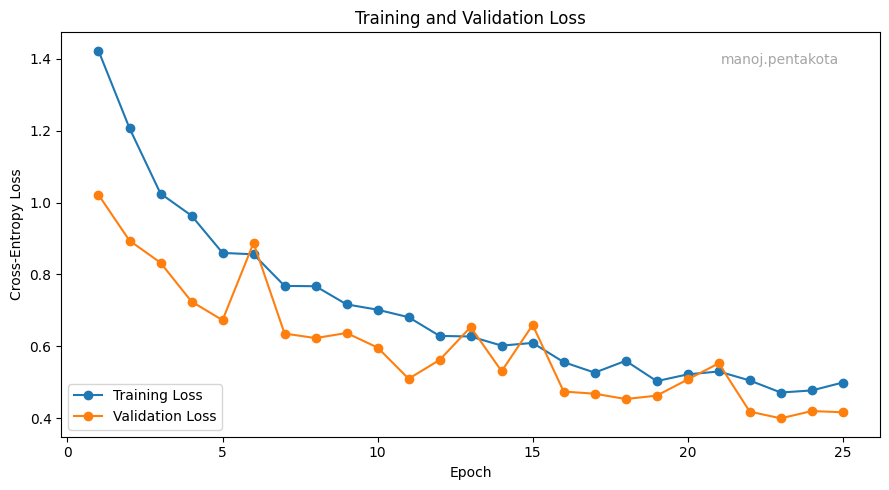

In [58]:
def plot_training_loss(history, username):
    epochs = range(1, len(history["train_loss"]) + 1)
    plt.figure(figsize=(9, 5))
    plt.plot(
        epochs,
        history["train_loss"],
        marker="o",
        label="Training Loss"
    )
    plt.plot(
        epochs,
        history["val_loss"],
        marker="o",
        label="Validation Loss"
    )
    plt.title("Training and Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Cross-Entropy Loss")
    plt.legend()
    plt.text(
        0.95, 0.95, username,
        ha="right", va="top",
        transform=plt.gca().transAxes,
        fontsize=10, color="gray", alpha=0.7
    )
    plt.tight_layout()
    plt.savefig("/content/checkpoints/loss_curve.png",dpi=300)
    plt.show()

plot_training_loss(trainer.history,EMAIL_USERNAME)

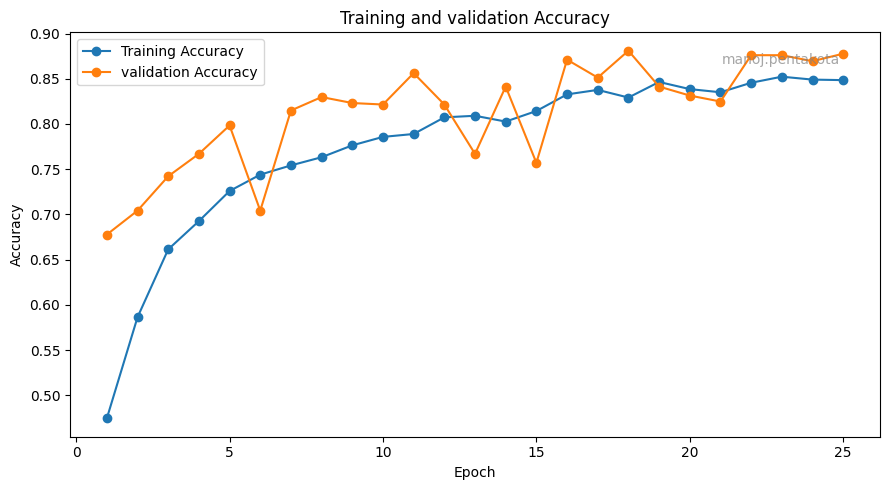

In [59]:
def plot_training_accuracy(history,username):
  epochs=range(1,len(history["train_accuracy"])+1)
  plt.figure(figsize=(9,5))
  plt.plot(
      epochs,
      history["train_accuracy"],
      marker="o",
      label="Training Accuracy"
  )
  plt.plot(
      epochs,
      history["val_accuracy"],
      marker="o",
      label="validation Accuracy"
  )
  plt.title("Training and validation Accuracy")
  plt.xlabel("Epoch")
  plt.ylabel("Accuracy")
  plt.legend()
  plt.text(
      0.95, 0.95, username,
      ha="right", va="top",
      transform=plt.gca().transAxes,
      fontsize=10, color="gray", alpha=0.7
  )
  plt.tight_layout()
  plt.savefig("/content/checkpoints/accuracy_curve.png",dpi=300)
  plt.show()

plot_training_accuracy(trainer.history,EMAIL_USERNAME)

In [60]:
checkpoint_path = "/content/checkpoints/best_model.pth"
checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE,
    weights_only=True
    )
model.load_state_dict(checkpoint["model_state_dict"])
model.to(DEVICE)
model.eval()
print("best checkpoint loaded successfully")
print("Best epoch:",checkpoint["epoch"])
print("Best validation accuray:",checkpoint["val_accuracy"])

best checkpoint loaded successfully
Best epoch: 18
Best validation accuray: 0.8809917355371901


In [61]:
part_c_results = {
    "seed": SEED,
    "architecture": "CartoonCNN",
    "input_shape": [3, 64, 64],
    "filters": FILTERS,
    "num_blocks": len(FILTERS),
    "num_classes": NUM_CLASSES,
    "dropout_rate": DROPOUT_RATE,
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "weight_decay": 0.0001,
    "batch_size": BATCH_SIZE,
    "max_epochs": 30,
    "best_epoch": trainer.best_epoch,
    "best_validation_accuracy": trainer.best_val_accuracy,
    "total_parameters": count_parameters(model),
    "model_size_mb": calculate_model_size(model)
}

with open("/content/checkpoints/part_c_results.json","w") as f:
    json.dump(part_c_results, f, indent=4)

display(
    pd.DataFrame(
        part_c_results.items(),
        columns=["Parameter", "Value"]
    )
)

print("Part C results saved!")

,Parameter,Value
0,seed,36
1,architecture,CartoonCNN
2,input_shape,"[3, 64, 64]"
3,filters,"[32, 64, 128]"
4,num_blocks,3
5,num_classes,6
6,dropout_rate,0.3
7,optimizer,Adam
8,learning_rate,0.001
9,weight_decay,0.0001


Part C results saved!


## Part D — Hyperparameter Tuning and Ablations

This section continues directly from Parts A–C. It reuses the cleaned splits, the cached `CartoonDataset`, the training-set normalisation statistics, and the `Trainer` class defined above.

**Protocol**

1. **Hyperparameter search.** Fifteen controlled runs explore the learning rate, optimiser (SGD, Adam, AdamW), dropout, weight decay, batch size, and the number / width of convolutional blocks. All search runs use 64×64 inputs and the same training/validation split.
2. **Ablation study.** One factor is changed at a time around the Part C baseline: augmentation on/off, BatchNorm on/off, dropout + weight decay on/off, and input resolution 32/64/96. Every configuration is repeated with **three random seeds**; results are reported as mean ± standard deviation of validation accuracy.
3. **Experiment logging.** Every run writes `config.json`, `history.csv`, `metrics.json`, and a best checkpoint under `/content/experiments/`. The combined log is saved as `experiment_log.csv`, and training/validation curves are plotted for every run.

The test set is **not** used for any tuning or ablation decision. The best configuration is selected by validation accuracy and evaluated on the test set exactly once at the end of Part D; Parts E and F reuse that single evaluation.

> Set `RESUME_EXPERIMENTS = False` in the next cell to force all runs to be retrained from scratch. With the default `True`, completed runs are loaded from disk, which makes the notebook resilient to Colab disconnects.


In [ ]:
# ============================================================
# Part D setup: experiment folders and protocol constants
# ============================================================

import json
import time
import hashlib
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms

EXPERIMENT_DIR = Path("/content/experiments")
RUNS_DIR = EXPERIMENT_DIR / "runs"
PLOTS_DIR = EXPERIMENT_DIR / "plots"
CHECKPOINTS_DIR = EXPERIMENT_DIR / "checkpoints"
for folder in [EXPERIMENT_DIR, RUNS_DIR, PLOTS_DIR, CHECKPOINTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Keep True to reuse completed runs after a runtime restart.
RESUME_EXPERIMENTS = True

SEARCH_EPOCHS = 10
SEARCH_PATIENCE = 4
ABLATION_EPOCHS = 12
ABLATION_PATIENCE = 4
FINAL_EPOCHS = 30
FINAL_PATIENCE = 7

SEARCH_SEED = SEED
ABLATION_SEEDS = [SEED, SEED + 1, SEED + 2]

print("Experiment root:", EXPERIMENT_DIR)
print("Search epochs:", SEARCH_EPOCHS, "| Ablation epochs:", ABLATION_EPOCHS)
print("Ablation seeds:", ABLATION_SEEDS)


In [ ]:
# ============================================================
# Configurable CNN and cached data pipeline for experiments
# ============================================================

class FlexibleConvBlock(nn.Module):
    """Conv -> optional BatchNorm -> ReLU -> MaxPool block."""

    def __init__(self, in_channels, out_channels, use_batchnorm=True):
        super().__init__()
        self.conv = nn.Conv2d(
            in_channels=in_channels,
            out_channels=out_channels,
            kernel_size=3,
            stride=1,
            padding=1,
            bias=not use_batchnorm,
        )
        self.bn = (
            nn.BatchNorm2d(out_channels)
            if use_batchnorm
            else nn.Identity()
        )
        self.relu = nn.ReLU(inplace=True)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

    def forward(self, x):
        x = self.conv(x)
        x = self.bn(x)
        x = self.relu(x)
        return self.pool(x)


class AblationCNN(nn.Module):
    """
    Configurable version of CartoonCNN for Parts D-F.

    With filters=(32, 64, 128), dropout_rate=0.3 and use_batchnorm=True,
    it is equivalent to the Part C architecture.
    """

    def __init__(
        self,
        num_classes=6,
        input_channels=3,
        filters=(32, 64, 128),
        dropout_rate=0.3,
        use_batchnorm=True,
    ):
        super().__init__()
        blocks = []
        in_channels = input_channels
        for out_channels in filters:
            blocks.append(
                FlexibleConvBlock(
                    in_channels,
                    out_channels,
                    use_batchnorm=use_batchnorm,
                )
            )
            in_channels = out_channels

        self.blocks = nn.ModuleList(blocks)
        self.global_pool = nn.AdaptiveAvgPool2d(output_size=1)
        self.dropout = nn.Dropout2d(p=dropout_rate)
        self.classifier = nn.Linear(in_channels, num_classes)
        self.initialize_weights()

    def initialize_weights(self):
        """Kaiming initialisation for convolutions and the classifier."""
        for module in self.modules():
            if isinstance(module, nn.Conv2d):
                nn.init.kaiming_normal_(
                    module.weight,
                    mode="fan_out",
                    nonlinearity="relu",
                )
                if module.bias is not None:
                    nn.init.zeros_(module.bias)
            elif isinstance(module, nn.Linear):
                nn.init.kaiming_normal_(
                    module.weight,
                    mode="fan_in",
                    nonlinearity="relu",
                )
                nn.init.zeros_(module.bias)

    def forward(self, x, return_features=False):
        """Return class logits and, optionally, the output of every block."""
        features = {}
        for index, block in enumerate(self.blocks, start=1):
            x = block(x)
            features[f"block{index}"] = x

        x = self.global_pool(x)
        x = self.dropout(x)
        x = torch.flatten(x, start_dim=1)
        logits = self.classifier(x)

        if return_features:
            return logits, features
        return logits


def normalize_image_size(image_size):
    """Return a square (width, height) tuple from an int or sequence."""
    if isinstance(image_size, (int, float)):
        return (int(image_size), int(image_size))
    if len(image_size) == 1:
        return (int(image_size[0]), int(image_size[0]))
    return (int(image_size[0]), int(image_size[1]))


def expand_config(config):
    """Fill defaults and normalise JSON-friendly configuration fields."""
    cfg = dict(config)
    cfg.setdefault("num_classes", NUM_CLASSES)
    cfg.setdefault("optimizer", "Adam")
    cfg.setdefault("learning_rate", 1e-3)
    cfg.setdefault("weight_decay", 1e-4)
    cfg.setdefault("momentum", 0.9)
    cfg.setdefault("dropout_rate", 0.3)
    cfg.setdefault("batch_size", 64)
    cfg.setdefault("filters", [32, 64, 128])
    cfg.setdefault("use_batchnorm", True)
    cfg.setdefault("use_augmentation", True)
    cfg.setdefault("image_size", 64)
    cfg.setdefault("seed", SEED)
    cfg["image_size"] = list(normalize_image_size(cfg["image_size"]))
    cfg["filters"] = [int(value) for value in cfg["filters"]]
    cfg["batch_size"] = int(cfg["batch_size"])
    cfg["seed"] = int(cfg["seed"])
    return cfg


def make_config(**overrides):
    """Build a complete experiment configuration."""
    return expand_config(overrides)


def build_model(config):
    """Instantiate AblationCNN from a configuration dictionary."""
    config = expand_config(config)
    return AblationCNN(
        num_classes=config["num_classes"],
        input_channels=INPUT_CHANNELS,
        filters=tuple(config["filters"]),
        dropout_rate=config["dropout_rate"],
        use_batchnorm=config["use_batchnorm"],
    )


class TransformSubset(Dataset):
    """
    Apply a transform on top of a cached CartoonDataset.

    The base dataset stores resized PIL images in memory, so different
    experiments do not have to decode and resize the same images again.
    """

    def __init__(self, base_dataset, transform):
        self.base_dataset = base_dataset
        self.transform = transform

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, index):
        image, label = self.base_dataset[index]
        if self.transform is not None:
            image = self.transform(image)
        return image, label


DATASET_CACHE = {}
TRANSFORM_CACHE = {}
NORMALIZATION_CACHE = {
    normalize_image_size(TARGET_SIZE): (
        CHANNEL_MEAN.tolist(),
        CHANNEL_STD.tolist(),
    )
}


def get_base_dataset(split, image_size):
    """Return (and cache) a resized CartoonDataset for one split."""
    size = normalize_image_size(image_size)
    key = (split, size)
    if key not in DATASET_CACHE:
        paths, labels = data_splits[split]
        DATASET_CACHE[key] = CartoonDataset(
            paths,
            labels,
            image_size=size,
        )
    return DATASET_CACHE[key]


def get_normalization_stats(image_size):
    """
    Compute per-channel training mean/std at a given resolution.

    The 64x64 statistics from Part B are reused. Other resolutions are
    computed from the training split only, so the resolution ablation does
    not accidentally use validation/test information.
    """
    size = normalize_image_size(image_size)
    if size in NORMALIZATION_CACHE:
        return NORMALIZATION_CACHE[size]

    base_dataset = get_base_dataset("train", size)
    to_tensor = transforms.ToTensor()
    channel_sum = torch.zeros(3, dtype=torch.float64)
    channel_squared_sum = torch.zeros(3, dtype=torch.float64)
    pixel_count = 0

    for image in tqdm(
        base_dataset.images,
        desc=f"Normalisation stats {size[0]}x{size[1]}",
        leave=False,
    ):
        tensor = to_tensor(image).double()
        channel_sum += tensor.sum(dim=(1, 2))
        channel_squared_sum += (tensor ** 2).sum(dim=(1, 2))
        pixel_count += tensor.shape[1] * tensor.shape[2]

    mean = channel_sum / pixel_count
    variance = (channel_squared_sum / pixel_count) - (mean ** 2)
    std = torch.sqrt(torch.clamp(variance, min=1e-12))

    NORMALIZATION_CACHE[size] = (mean.tolist(), std.tolist())
    return NORMALIZATION_CACHE[size]


def get_transforms(image_size):
    """Return training (augmented) and evaluation transforms."""
    size = normalize_image_size(image_size)
    if size in TRANSFORM_CACHE:
        return TRANSFORM_CACHE[size]

    mean, std = get_normalization_stats(size)

    train_transform = transforms.Compose([
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(degrees=10, fill=(255, 255, 255)),
        transforms.ColorJitter(
            brightness=0.15,
            contrast=0.15,
            saturation=0.15,
            hue=0.15,
        ),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
    ])
    eval_transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
    ])

    TRANSFORM_CACHE[size] = (train_transform, eval_transform)
    return TRANSFORM_CACHE[size]


SAMPLE_WEIGHTS = [
    1.0 / train_class_counts[int(label)]
    for label in train_labels
]


def make_loader(
    split,
    image_size,
    batch_size,
    use_augmentation,
    num_workers=NUM_WORKERS,
):
    """Build a DataLoader over the cached, resized dataset."""
    size = normalize_image_size(image_size)
    base_dataset = get_base_dataset(split, size)
    train_transform, eval_transform = get_transforms(size)
    transform = (
        train_transform
        if split == "train" and use_augmentation
        else eval_transform
    )
    dataset = TransformSubset(base_dataset, transform)

    common_kwargs = {
        "batch_size": int(batch_size),
        "num_workers": num_workers,
        "pin_memory": (DEVICE.type == "cuda"),
    }

    if split == "train" and USE_WEIGHTED_SAMPLER:
        sampler = WeightedRandomSampler(
            weights=SAMPLE_WEIGHTS,
            num_samples=len(SAMPLE_WEIGHTS),
            replacement=True,
        )
        return dataset, DataLoader(
            dataset,
            sampler=sampler,
            **common_kwargs,
        )

    return dataset, DataLoader(
        dataset,
        shuffle=(split == "train"),
        **common_kwargs,
    )


In [ ]:
# ============================================================
# Run identifiers, logging, and a single training entry point
# ============================================================

def config_to_json(config):
    """Serialise a configuration deterministically (ignoring metadata keys)."""
    clean = {
        key: value
        for key, value in config.items()
        if not key.startswith("_")
    }
    return json.dumps(clean, sort_keys=True, default=str)


def make_run_id(prefix, config):
    """Stable short identifier for a run configuration."""
    digest = hashlib.md5(
        config_to_json(config).encode("utf-8")
    ).hexdigest()[:10]
    return f"{prefix}_{digest}"


def load_run_config(run_id):
    """Load the configuration stored for a run."""
    with open(RUNS_DIR / run_id / "config.json", "r") as handle:
        return json.load(handle)


def train_config(
    config,
    max_epochs,
    patience,
    prefix,
    label=None,
):
    """
    Train one configuration and persist its configuration, history and metrics.

    Returns a dictionary containing the run id, history, metrics and, for a
    freshly trained run, the trained model. Completed runs are skipped when
    RESUME_EXPERIMENTS is True.
    """
    config = expand_config(config)
    run_config = {
        key: value
        for key, value in config.items()
        if not key.startswith("_")
    }
    run_id = make_run_id(prefix, run_config)
    run_dir = RUNS_DIR / run_id
    run_dir.mkdir(parents=True, exist_ok=True)

    history_path = run_dir / "history.csv"
    metrics_path = run_dir / "metrics.json"
    config_path = run_dir / "config.json"
    checkpoint_path = CHECKPOINTS_DIR / f"{run_id}.pth"
    run_label = label or prefix

    if (
        RESUME_EXPERIMENTS
        and history_path.exists()
        and metrics_path.exists()
        and config_path.exists()
        and checkpoint_path.exists()
    ):
        history = pd.read_csv(history_path)
        with open(metrics_path, "r") as handle:
            metrics = json.load(handle)
        print(
            f"[cached] {run_label} ({run_id}) | "
            f"val acc = {metrics['best_val_accuracy']:.4f}"
        )
        return {
            "run_id": run_id,
            "config": run_config,
            "history": history,
            "metrics": metrics,
            "model": None,
            "checkpoint_path": str(checkpoint_path),
            "skipped": True,
        }

    set_seed(run_config["seed"])
    image_size = normalize_image_size(run_config["image_size"])

    _, train_loader_run = make_loader(
        "train",
        image_size,
        run_config["batch_size"],
        run_config["use_augmentation"],
    )
    _, val_loader_run = make_loader(
        "validation",
        image_size,
        run_config["batch_size"],
        use_augmentation=False,
    )

    model = build_model(run_config).to(DEVICE)
    trainer = Trainer(
        model=model,
        train_loader=train_loader_run,
        val_loader=val_loader_run,
        optimizer_name=run_config["optimizer"],
        learning_rate=run_config["learning_rate"],
        weight_decay=run_config["weight_decay"],
        momentum=run_config["momentum"],
        patience=patience,
        max_epochs=max_epochs,
        checkpoint_path=str(checkpoint_path),
        device=DEVICE,
    )

    start_time = time.time()
    history = trainer.fit()
    elapsed = time.time() - start_time

    # A pathological configuration can finish without ever improving on the
    # initial best score of 0.0, in which case the Trainer saves no checkpoint.
    # Persist the final state so that every logged run remains loadable.
    if not checkpoint_path.exists():
        torch.save(
            {
                "epoch": int(len(history)),
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": trainer.optimizer.state_dict(),
                "val_accuracy": float(trainer.best_val_accuracy),
            },
            checkpoint_path,
        )

    # Reload the best checkpoint: the returned model is the one selected by
    # validation accuracy, not necessarily the last epoch.
    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=True,
    )
    model.load_state_dict(checkpoint["model_state_dict"])
    model.to(DEVICE)
    model.eval()

    metrics = {
        "run_id": run_id,
        "phase": prefix,
        "label": run_label,
        "seed": run_config["seed"],
        "optimizer": run_config["optimizer"],
        "learning_rate": run_config["learning_rate"],
        "weight_decay": run_config["weight_decay"],
        "momentum": run_config["momentum"],
        "dropout_rate": run_config["dropout_rate"],
        "batch_size": run_config["batch_size"],
        "filters": run_config["filters"],
        "num_blocks": len(run_config["filters"]),
        "use_batchnorm": run_config["use_batchnorm"],
        "use_augmentation": run_config["use_augmentation"],
        "image_size": run_config["image_size"][0],
        "best_val_accuracy": float(trainer.best_val_accuracy),
        "best_epoch": int(trainer.best_epoch),
        "epochs_run": int(len(history)),
        "train_time_sec": float(elapsed),
        "total_parameters": int(count_parameters(model)),
        "model_size_mb": float(calculate_model_size(model)),
        "ablation_group": config.get("_ablation_group"),
        "ablation_level": config.get("_ablation_level"),
    }

    history.to_csv(history_path, index=False)
    with open(config_path, "w") as handle:
        json.dump(run_config, handle, indent=2)
    with open(metrics_path, "w") as handle:
        json.dump(metrics, handle, indent=2)

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    print(
        f"[done] {run_label} ({run_id}) | "
        f"val acc = {metrics['best_val_accuracy']:.4f} | "
        f"best epoch = {metrics['best_epoch']} | "
        f"{metrics['train_time_sec']:.1f}s"
    )

    return {
        "run_id": run_id,
        "config": run_config,
        "history": history,
        "metrics": metrics,
        "model": model,
        "checkpoint_path": str(checkpoint_path),
        "skipped": False,
    }


@torch.no_grad()
def collect_logits(model, loader):
    """Collect logits and labels for a DataLoader without shuffling."""
    model.eval()
    logits_list = []
    labels_list = []
    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        logits_list.append(model(images).detach().cpu())
        labels_list.append(labels.detach().cpu())
    return (
        torch.cat(logits_list, dim=0).numpy(),
        torch.cat(labels_list, dim=0).numpy(),
    )


### D.1 Hyperparameter search

The search deliberately changes one factor at a time where possible, so the effect of each hyperparameter is visible. It covers every factor requested in the assignment: learning rate, optimiser, dropout, weight decay, batch size, and number of filters/blocks. Each configuration is trained for at most 10 epochs with early stopping (patience 4), which keeps the full search practical on a Colab T4 while still separating clearly bad configurations from good ones.


In [ ]:
# Hyperparameter search configurations.
SEARCH_CONFIGS = [
    ("Adam, lr=1e-3 (baseline)", {}),
    ("Adam, lr=3e-4", {"learning_rate": 3e-4}),
    ("Adam, lr=3e-3", {"learning_rate": 3e-3}),
    ("SGD, lr=1e-2", {"optimizer": "SGD", "learning_rate": 1e-2}),
    ("SGD, lr=1e-3", {"optimizer": "SGD", "learning_rate": 1e-3}),
    (
        "AdamW, lr=1e-3, wd=1e-2",
        {"optimizer": "AdamW", "learning_rate": 1e-3, "weight_decay": 1e-2},
    ),
    (
        "AdamW, lr=3e-4, wd=1e-2",
        {"optimizer": "AdamW", "learning_rate": 3e-4, "weight_decay": 1e-2},
    ),
    ("Dropout 0.1", {"dropout_rate": 0.1}),
    ("Dropout 0.5", {"dropout_rate": 0.5}),
    ("Weight decay 0", {"weight_decay": 0.0}),
    ("Batch size 32", {"batch_size": 32}),
    ("Batch size 128", {"batch_size": 128}),
    ("Small filters [16,32,64]", {"filters": [16, 32, 64]}),
    ("Large filters [48,96,192]", {"filters": [48, 96, 192]}),
    ("Four blocks [32,64,128,256]", {"filters": [32, 64, 128, 256]}),
]

search_results = []
for search_label, overrides in tqdm(
    SEARCH_CONFIGS,
    desc="Hyperparameter search",
):
    config = make_config(seed=SEARCH_SEED, **overrides)
    result = train_config(
        config,
        max_epochs=SEARCH_EPOCHS,
        patience=SEARCH_PATIENCE,
        prefix="search",
        label=search_label,
    )
    search_results.append(result)

search_df = pd.DataFrame([
    result["metrics"] for result in search_results
])
search_df = (
    search_df
    .sort_values("best_val_accuracy", ascending=False)
    .reset_index(drop=True)
)
search_df.to_csv(EXPERIMENT_DIR / "search_results.csv", index=False)

search_display_columns = [
    "label",
    "optimizer",
    "learning_rate",
    "weight_decay",
    "dropout_rate",
    "batch_size",
    "filters",
    "num_blocks",
    "best_val_accuracy",
    "best_epoch",
    "train_time_sec",
    "total_parameters",
]
display(search_df[search_display_columns])

best_search = search_df.iloc[0]
display(Markdown(f"""
**Best hyperparameter-search run:** `{best_search['label']}` with validation accuracy **{best_search['best_val_accuracy']:.4f}** (best epoch {int(best_search['best_epoch'])}).
"""))


In [ ]:
# ============================================================
# Search visualisations: ranking and per-run curves
# ============================================================

def plot_search_ranking(results_df, save_path):
    """Bar chart of validation accuracy for every hyperparameter run."""
    data = results_df.sort_values("best_val_accuracy", ascending=True)
    plt.figure(figsize=(10, 7))
    plt.barh(
        data["label"],
        data["best_val_accuracy"],
        color="#4C72B0",
        edgecolor="black",
        linewidth=0.5,
    )
    plt.xlabel("Best validation accuracy")
    plt.ylabel("Configuration")
    plt.title("Hyperparameter Search: Validation Accuracy")
    plt.xlim(0, 1)
    for index, value in enumerate(data["best_val_accuracy"]):
        plt.text(
            value + 0.005,
            index,
            f"{value:.3f}",
            va="center",
            fontsize=8,
        )
    plt.text(
        0.99, 0.99, EMAIL_USERNAME,
        ha="right", va="top",
        transform=plt.gca().transAxes,
        fontsize=10, color="gray", alpha=0.7,
    )
    plt.tight_layout()
    plt.savefig(save_path, dpi=300)
    plt.show()


def plot_history_grid(records, metric, title, save_path, ncols=4):
    """
    Plot training/validation curves for every run in a grid.

    records: list of (run_id, label) tuples.
    metric: "loss" or "accuracy".
    """
    n_runs = len(records)
    nrows = int(np.ceil(n_runs / ncols))
    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(4.2 * ncols, 2.8 * nrows),
    )
    axes = np.array(axes).reshape(-1)

    for axis, (run_id, label) in zip(axes, records):
        history = pd.read_csv(RUNS_DIR / run_id / "history.csv")
        epochs = np.arange(1, len(history) + 1)
        if metric == "loss":
            axis.plot(epochs, history["train_loss"], label="train", linewidth=1.5)
            axis.plot(epochs, history["val_loss"], label="validation", linewidth=1.5)
            axis.set_ylabel("Cross-entropy loss")
        else:
            axis.plot(epochs, history["train_accuracy"], label="train", linewidth=1.5)
            axis.plot(epochs, history["val_accuracy"], label="validation", linewidth=1.5)
            axis.set_ylabel("Accuracy")
        axis.set_title(label, fontsize=8)
        axis.set_xlabel("Epoch")
        axis.legend(fontsize=6, loc="best")

    for axis in axes[n_runs:]:
        axis.axis("off")

    fig.suptitle(title, fontsize=14)
    fig.text(
        0.99, 0.99, EMAIL_USERNAME,
        ha="right", va="top",
        fontsize=10, color="gray", alpha=0.7,
    )
    plt.tight_layout()
    plt.savefig(save_path, dpi=250, bbox_inches="tight")
    plt.show()


plot_search_ranking(
    search_df,
    PLOTS_DIR / "search_validation_accuracy.png",
)

search_curve_records = [
    (result["run_id"], result["metrics"]["label"])
    for result in search_results
]
plot_history_grid(
    search_curve_records,
    metric="loss",
    title="Hyperparameter Search: Training and Validation Loss",
    save_path=PLOTS_DIR / "search_loss_curves.png",
)
plot_history_grid(
    search_curve_records,
    metric="accuracy",
    title="Hyperparameter Search: Training and Validation Accuracy",
    save_path=PLOTS_DIR / "search_accuracy_curves.png",
)


### D.2 Ablation study

The ablation uses the Part C configuration as the fixed reference: 3 conv–BN–ReLU–pool blocks with 32/64/128 filters, dropout 0.3, weight decay \(10^{-4}\), Adam at \(10^{-3}\), batch size 64, 64×64 input, and the Part B augmentation pipeline. Each row below changes **only one factor** and keeps everything else at that reference. The reference run is reused across the augmentation, BatchNorm, regularisation, and 64×64 resolution comparisons, so it is trained once per seed rather than duplicated.

Three seeds are used for every unique configuration. The reported uncertainty is the sample standard deviation of the best validation accuracy across those seeds.


In [ ]:
# ============================================================
# Ablation runs: one factor at a time, three seeds per configuration
# ============================================================

ABLATION_SPECS = [
    {
        "group": "Data augmentation",
        "level": "With augmentation (baseline)",
        "overrides": {},
    },
    {
        "group": "Data augmentation",
        "level": "Without augmentation",
        "overrides": {"use_augmentation": False},
    },
    {
        "group": "BatchNorm",
        "level": "With BatchNorm (baseline)",
        "overrides": {},
    },
    {
        "group": "BatchNorm",
        "level": "Without BatchNorm",
        "overrides": {"use_batchnorm": False},
    },
    {
        "group": "Dropout + weight decay",
        "level": "With dropout=0.3, wd=1e-4 (baseline)",
        "overrides": {},
    },
    {
        "group": "Dropout + weight decay",
        "level": "Without dropout/wd",
        "overrides": {"dropout_rate": 0.0, "weight_decay": 0.0},
    },
    {
        "group": "Image resolution",
        "level": "32 x 32",
        "overrides": {"image_size": 32},
    },
    {
        "group": "Image resolution",
        "level": "64 x 64 (baseline)",
        "overrides": {},
    },
    {
        "group": "Image resolution",
        "level": "96 x 96",
        "overrides": {"image_size": 96},
    },
]

ablation_membership = []
ablation_unique = {}

for spec in tqdm(ABLATION_SPECS, desc="Ablation configurations"):
    for seed in ABLATION_SEEDS:
        config = make_config(seed=seed, **spec["overrides"])
        config["_ablation_group"] = spec["group"]
        config["_ablation_level"] = spec["level"]

        run_config = {
            key: value
            for key, value in config.items()
            if not key.startswith("_")
        }
        run_id = make_run_id("ablation", run_config)

        if run_id in ablation_unique:
            result = ablation_unique[run_id]["result"]
        else:
            result = train_config(
                config,
                max_epochs=ABLATION_EPOCHS,
                patience=ABLATION_PATIENCE,
                prefix="ablation",
                label=f"{spec['group']}: {spec['level']}",
            )
            ablation_unique[run_id] = {
                "result": result,
                "group": spec["group"],
                "level": spec["level"],
            }

        ablation_membership.append({
            "run_id": run_id,
            "ablation_group": spec["group"],
            "ablation_level": spec["level"],
            "seed": seed,
        })

ablation_membership_df = pd.DataFrame(ablation_membership)
ablation_metrics_df = (
    pd.DataFrame([
        entry["result"]["metrics"]
        for entry in ablation_unique.values()
    ])
    .drop_duplicates("run_id")
)

ablation_long_df = ablation_membership_df.merge(
    ablation_metrics_df.drop(
        columns=["seed", "ablation_group", "ablation_level"]
    ),
    on="run_id",
    how="left",
)

ablation_summary = (
    ablation_long_df
    .groupby(["ablation_group", "ablation_level"])
    .agg(
        mean_val_accuracy=("best_val_accuracy", "mean"),
        std_val_accuracy=("best_val_accuracy", "std"),
        n_seeds=("seed", "nunique"),
        mean_train_time_sec=("train_time_sec", "mean"),
        mean_parameters=("total_parameters", "mean"),
    )
    .reset_index()
)
ablation_summary["val_accuracy"] = ablation_summary.apply(
    lambda row: (
        f"{row['mean_val_accuracy']:.4f} "
        f"± {row['std_val_accuracy']:.4f}"
    ),
    axis=1,
)

FACTOR_ORDER = {
    "Data augmentation": 0,
    "BatchNorm": 1,
    "Dropout + weight decay": 2,
    "Image resolution": 3,
}
LEVEL_ORDER = {
    "With augmentation (baseline)": 0,
    "Without augmentation": 1,
    "With BatchNorm (baseline)": 0,
    "Without BatchNorm": 1,
    "With dropout=0.3, wd=1e-4 (baseline)": 0,
    "Without dropout/wd": 1,
    "32 x 32": 0,
    "64 x 64 (baseline)": 1,
    "96 x 96": 2,
}
ablation_summary["_factor_order"] = (
    ablation_summary["ablation_group"].map(FACTOR_ORDER)
)
ablation_summary["_level_order"] = (
    ablation_summary["ablation_level"].map(LEVEL_ORDER)
)
ablation_summary = (
    ablation_summary
    .sort_values(["_factor_order", "_level_order"])
    .drop(columns=["_factor_order", "_level_order"])
    .reset_index(drop=True)
)

ablation_summary.to_csv(
    EXPERIMENT_DIR / "ablation_summary.csv",
    index=False,
)
ablation_metrics_df.to_csv(
    EXPERIMENT_DIR / "ablation_runs.csv",
    index=False,
)

display(
    ablation_summary[
        [
            "ablation_group",
            "ablation_level",
            "n_seeds",
            "val_accuracy",
            "mean_train_time_sec",
            "mean_parameters",
        ]
    ]
)

best_ablation = ablation_summary.sort_values(
    "mean_val_accuracy",
    ascending=False,
).iloc[0]
display(Markdown(f"""
**Best ablation configuration:** `{best_ablation['ablation_group']} — {best_ablation['ablation_level']}` with mean validation accuracy **{best_ablation['mean_val_accuracy']:.4f} ± {best_ablation['std_val_accuracy']:.4f}** over {int(best_ablation['n_seeds'])} seeds.
"""))


In [ ]:
# ============================================================
# Ablation table plot with error bars and per-run curves
# ============================================================

def plot_ablation_bars(summary_df, save_path):
    """Four-panel bar plot of mean validation accuracy with std error bars."""
    groups = [
        "Data augmentation",
        "BatchNorm",
        "Dropout + weight decay",
        "Image resolution",
    ]
    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    axes = axes.flatten()
    palette = sns.color_palette("muted", 3)

    for axis, group in zip(axes, groups):
        data = summary_df[summary_df["ablation_group"] == group].copy()
        data["_level_order"] = data["ablation_level"].map(LEVEL_ORDER)
        data = data.sort_values("_level_order")
        x_positions = np.arange(len(data))

        axis.bar(
            x_positions,
            data["mean_val_accuracy"],
            yerr=data["std_val_accuracy"],
            capsize=5,
            color=[
                palette[index % len(palette)]
                for index in range(len(data))
            ],
            edgecolor="black",
            linewidth=0.6,
        )
        axis.set_xticks(x_positions)
        axis.set_xticklabels(
            data["ablation_level"],
            rotation=15,
            ha="right",
            fontsize=8,
        )
        axis.set_ylim(0, 1.0)
        axis.set_ylabel("Validation accuracy")
        axis.set_title(group)

        for index, (_, row) in enumerate(data.iterrows()):
            axis.text(
                index,
                min(
                    row["mean_val_accuracy"] + row["std_val_accuracy"] + 0.02,
                    0.98,
                ),
                f"{row['mean_val_accuracy']:.3f}",
                ha="center",
                va="bottom",
                fontsize=8,
            )

    fig.suptitle(
        "Ablation Study: Mean ± Std Validation Accuracy (3 Seeds)",
        fontsize=14,
    )
    fig.text(
        0.99, 0.99, EMAIL_USERNAME,
        ha="right", va="top",
        fontsize=10, color="gray", alpha=0.7,
    )
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()


plot_ablation_bars(
    ablation_summary,
    PLOTS_DIR / "ablation_error_bars.png",
)

ablation_curve_records = []
for entry in ablation_unique.values():
    result = entry["result"]
    ablation_curve_records.append(
        (
            result["run_id"],
            (
                f"{entry['group']} | {entry['level']} | "
                f"seed {result['metrics']['seed']}"
            ),
        )
    )

plot_history_grid(
    ablation_curve_records,
    metric="loss",
    title="Ablation Runs: Training and Validation Loss",
    save_path=PLOTS_DIR / "ablation_loss_curves.png",
)
plot_history_grid(
    ablation_curve_records,
    metric="accuracy",
    title="Ablation Runs: Training and Validation Accuracy",
    save_path=PLOTS_DIR / "ablation_accuracy_curves.png",
)


In [ ]:
# ============================================================
# Combined experiment log (CSV/JSON) for every search and ablation run
# ============================================================

all_run_metrics = pd.concat(
    [search_df, ablation_metrics_df],
    ignore_index=True,
).drop_duplicates("run_id")
all_run_metrics.to_csv(
    EXPERIMENT_DIR / "experiment_log.csv",
    index=False,
)

with open(EXPERIMENT_DIR / "experiment_log.json", "w") as handle:
    json.dump(
        all_run_metrics.to_dict(orient="records"),
        handle,
        indent=2,
        default=str,
    )

print("Experiment log written to:", EXPERIMENT_DIR / "experiment_log.csv")
print("Total unique runs logged:", len(all_run_metrics))
display(
    all_run_metrics[
        [
            "run_id",
            "phase",
            "label",
            "seed",
            "image_size",
            "use_augmentation",
            "use_batchnorm",
            "best_val_accuracy",
            "train_time_sec",
        ]
    ].sort_values("best_val_accuracy", ascending=False).head(20)
)


### D.3 Final model selection and single test evaluation

The best configuration is chosen **only by validation accuracy** across the search and ablation runs. It is then retrained from scratch with a longer schedule (30 epochs, early-stopping patience 7) and evaluated on the test set exactly once. The resulting checkpoint is the model used in Parts E and F.


In [ ]:
# ============================================================
# Select the best validation configuration, retrain, and test once
# ============================================================

best_run = all_run_metrics.sort_values(
    "best_val_accuracy",
    ascending=False,
).iloc[0]

FINAL_CONFIG = expand_config(
    load_run_config(best_run["run_id"])
)

print("Selected run:", best_run["run_id"])
print(
    "Selected configuration:",
    json.dumps(FINAL_CONFIG, indent=2, default=str),
)

final_result = train_config(
    FINAL_CONFIG,
    max_epochs=FINAL_EPOCHS,
    patience=FINAL_PATIENCE,
    prefix="final",
    label="final_selected_config",
)
FINAL_CONFIG = final_result["config"]

# Add the final retrained run to the combined experiment log as well.
all_run_metrics = pd.concat(
    [all_run_metrics, pd.DataFrame([final_result["metrics"]])],
    ignore_index=True,
).drop_duplicates("run_id")
all_run_metrics.to_csv(
    EXPERIMENT_DIR / "experiment_log.csv",
    index=False,
)
with open(EXPERIMENT_DIR / "experiment_log.json", "w") as handle:
    json.dump(
        all_run_metrics.to_dict(orient="records"),
        handle,
        indent=2,
        default=str,
    )

FINAL_MODEL = build_model(FINAL_CONFIG).to(DEVICE)
final_checkpoint = torch.load(
    final_result["checkpoint_path"],
    map_location=DEVICE,
    weights_only=True,
)
FINAL_MODEL.load_state_dict(final_checkpoint["model_state_dict"])
FINAL_MODEL.to(DEVICE)
FINAL_MODEL.eval()

final_size = normalize_image_size(FINAL_CONFIG["image_size"])
FINAL_EVAL_BATCH_SIZE = 128

_, final_val_loader = make_loader(
    "validation",
    final_size,
    FINAL_EVAL_BATCH_SIZE,
    use_augmentation=False,
)
_, final_test_loader = make_loader(
    "test",
    final_size,
    FINAL_EVAL_BATCH_SIZE,
    use_augmentation=False,
)

FINAL_VAL_LOGITS, FINAL_VAL_LABELS = collect_logits(
    FINAL_MODEL,
    final_val_loader,
)
FINAL_TEST_LOGITS, FINAL_TEST_LABELS = collect_logits(
    FINAL_MODEL,
    final_test_loader,
)

FINAL_TEST_PROBS = torch.softmax(
    torch.tensor(FINAL_TEST_LOGITS),
    dim=1,
).numpy()
FINAL_TEST_PREDS = FINAL_TEST_PROBS.argmax(axis=1)

from sklearn.metrics import accuracy_score, f1_score

final_val_accuracy = accuracy_score(
    FINAL_VAL_LABELS,
    FINAL_VAL_LOGITS.argmax(axis=1),
)
final_test_accuracy = accuracy_score(
    FINAL_TEST_LABELS,
    FINAL_TEST_PREDS,
)
final_test_macro_f1 = f1_score(
    FINAL_TEST_LABELS,
    FINAL_TEST_PREDS,
    average="macro",
)

final_selection = {
    "selected_run_id": best_run["run_id"],
    "selected_from_phase": best_run["phase"],
    "config": FINAL_CONFIG,
    "retrained_val_accuracy": float(final_val_accuracy),
    "test_accuracy": float(final_test_accuracy),
    "test_macro_f1": float(final_test_macro_f1),
    "test_evaluated_once": True,
}
with open(EXPERIMENT_DIR / "final_selection.json", "w") as handle:
    json.dump(final_selection, handle, indent=2)

display(Markdown(f"""
### Selected model

- Selected run: `{best_run['run_id']}` ({best_run['phase']}; original validation accuracy = **{best_run['best_val_accuracy']:.4f}**)
- Architecture: {len(FINAL_CONFIG['filters'])} blocks, filters `{FINAL_CONFIG['filters']}`, BatchNorm = **{FINAL_CONFIG['use_batchnorm']}**
- Optimiser: **{FINAL_CONFIG['optimizer']}**, learning rate = **{FINAL_CONFIG['learning_rate']}**, weight decay = **{FINAL_CONFIG['weight_decay']}**
- Dropout = **{FINAL_CONFIG['dropout_rate']}**, batch size = **{FINAL_CONFIG['batch_size']}**, resolution = **{FINAL_CONFIG['image_size'][0]}×{FINAL_CONFIG['image_size'][1]}**
- Retrained validation accuracy = **{final_val_accuracy:.4f}**
- Test accuracy (evaluated once) = **{final_test_accuracy:.4f}**
- Test macro-F1 = **{final_test_macro_f1:.4f}**

The test predictions and logits from this cell are reused in Parts E and F; the test set is not evaluated again for model selection.
"""))


## Part E — Evaluation and Error Analysis

This section evaluates the single model selected in Part D. The test set is used only here, after all model selection is complete.

The analysis covers:

1. overall test accuracy, per-class precision/recall/F1, and macro-F1;
2. the normalised confusion matrix, the two most-confused class pairs, and a grid of misclassified test images;
3. calibration: a 15-bin reliability diagram, Expected Calibration Error (ECE), and temperature scaling fitted on the validation set;
4. a classical baseline on exactly the same splits, compared with the CNN using McNemar's test and a bootstrap confidence interval for the accuracy difference.


In [ ]:
# ============================================================
# E.1 Test metrics: accuracy, per-class precision/recall/F1, macro-F1
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    f1_score,
    classification_report,
    confusion_matrix,
)

FINAL_TEST_PREDS = FINAL_TEST_PROBS.argmax(axis=1)

overall_accuracy = accuracy_score(
    FINAL_TEST_LABELS,
    FINAL_TEST_PREDS,
)
macro_f1 = f1_score(
    FINAL_TEST_LABELS,
    FINAL_TEST_PREDS,
    average="macro",
)
weighted_f1 = f1_score(
    FINAL_TEST_LABELS,
    FINAL_TEST_PREDS,
    average="weighted",
)

precision, recall, f1, support = precision_recall_fscore_support(
    FINAL_TEST_LABELS,
    FINAL_TEST_PREDS,
    labels=np.arange(len(CLASSES)),
    zero_division=0,
)

per_class_df = pd.DataFrame({
    "class": CLASSES,
    "precision": precision,
    "recall": recall,
    "f1": f1,
    "support": support,
})
display(per_class_df)

print(classification_report(
    FINAL_TEST_LABELS,
    FINAL_TEST_PREDS,
    labels=np.arange(len(CLASSES)),
    target_names=CLASSES,
    digits=4,
    zero_division=0,
))

display(Markdown(f"""
### Overall test metrics

| Metric | Value |
|---|---|
| Accuracy | **{overall_accuracy:.4f}** |
| Macro-F1 | **{macro_f1:.4f}** |
| Weighted-F1 | **{weighted_f1:.4f}** |
| Test images | **{len(FINAL_TEST_LABELS)}** |

Macro-F1 weights every character equally, so it is the more informative summary when class support differs.
"""))


In [ ]:
# ============================================================
# E.2 Confusion matrix, most-confused pairs, and error examples
# ============================================================

cm = confusion_matrix(
    FINAL_TEST_LABELS,
    FINAL_TEST_PREDS,
    labels=np.arange(len(CLASSES)),
)
cm_normalized = cm.astype(np.float64) / np.clip(
    cm.sum(axis=1, keepdims=True),
    1,
    None,
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=CLASSES,
    yticklabels=CLASSES,
    vmin=0,
    vmax=1,
    cbar_kws={"label": "Row-normalised proportion"},
)
plt.title("Normalised Confusion Matrix — Final Model")
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.text(
    0.99, 0.99, EMAIL_USERNAME,
    ha="right", va="top",
    transform=plt.gca().transAxes,
    fontsize=10, color="gray", alpha=0.7,
)
plt.tight_layout()
plt.savefig(
    PLOTS_DIR / "confusion_matrix_normalized.png",
    dpi=300,
)
plt.show()

# Two most-confused unordered class pairs, using both off-diagonal directions.
pair_scores = []
for i in range(len(CLASSES)):
    for j in range(i + 1, len(CLASSES)):
        combined_rate = cm_normalized[i, j] + cm_normalized[j, i]
        pair_scores.append({
            "class_a": CLASSES[i],
            "class_b": CLASSES[j],
            "combined_normalised_rate": float(combined_rate),
            "a_predicted_as_b": int(cm[i, j]),
            "b_predicted_as_a": int(cm[j, i]),
        })

pair_scores_df = pd.DataFrame(pair_scores).sort_values(
    "combined_normalised_rate",
    ascending=False,
).reset_index(drop=True)
top_pairs_df = pair_scores_df.head(2)
display(top_pairs_df)

CONFUSION_CAUSES = {
    frozenset(["donald", "mickey"]): (
        "Both are Disney mascots with large eyes and rounded head silhouettes; "
        "at low resolution the beak/ears and face proportions become the main "
        "cues, and these are easily blurred by padding or rotation."
    ),
    frozenset(["mickey", "minion"]): (
        "Both have large eyes and rounded heads, and the Minions' yellow/tan "
        "skin can resemble Mickey's face colour. Goggles versus round ears are "
        "a fine-grained cue that is often lost at 64×64."
    ),
    frozenset(["pooh", "pumba"]): (
        "Both classes are dominated by brown/tan colours and rounded body "
        "shapes, so colour histograms and coarse silhouettes overlap."
    ),
    frozenset(["donald", "olaf"]): (
        "Both characters contain large white/light regions; the model can rely "
        "on overall brightness instead of the distinctive beak or carrot nose."
    ),
    frozenset(["minion", "pumba"]): (
        "Yellow/brown colour patches and rounded shapes overlap; the absence of "
        "a strong background cue makes this pair difficult."
    ),
    frozenset(["mickey", "olaf"]): (
        "Large light face regions and rounded heads can dominate the low-level "
        "features, while the distinguishing ears/nose are small."
    ),
    frozenset(["donald", "minion"]): (
        "Similar warm colour patches and rounded head shapes can confuse the "
        "classifier when the character occupies a small part of the frame."
    ),
    frozenset(["olaf", "pooh"]): (
        "Both are bright, low-contrast characters; the model may focus on "
        "background colour rather than the character's distinctive parts."
    ),
    frozenset(["mickey", "pooh"]): (
        "Rounded heads and warm face colours overlap, especially when the "
        "character is small or partially occluded."
    ),
    frozenset(["donald", "pooh"]): (
        "Warm body colours and rounded silhouettes overlap; the beak is the "
        "main discriminative cue and it is small at low resolution."
    ),
    frozenset(["donald", "pumba"]): (
        "Dark/warm colour regions and rounded bodies overlap; the model may "
        "use background context instead of character-specific parts."
    ),
    frozenset(["mickey", "pumba"]): (
        "Coarse shape and colour statistics overlap; the classes are visually "
        "far apart, so errors usually indicate a small/occluded character."
    ),
    frozenset(["minion", "olaf"]): (
        "Both are bright characters with rounded heads; colour is the main "
        "separator, and colour jitter or unusual lighting weakens it."
    ),
    frozenset(["minion", "pooh"]): (
        "Yellow/warm colours and rounded bodies overlap, especially in images "
        "with several characters or a busy background."
    ),
    frozenset(["olaf", "pumba"]): (
        "The classes differ strongly in colour, so errors here usually come "
        "from an unusual background, occlusion, or a very small character."
    ),
}


def describe_confusion(class_a, class_b):
    """Return a short plausible cause for a confused class pair."""
    return CONFUSION_CAUSES.get(
        frozenset([class_a, class_b]),
        (
            "The pair shares colour, shape, or background statistics; inspect "
            "the misclassified examples above to identify the dominant cue."
        ),
    )


pair_lines = []
for _, row in top_pairs_df.iterrows():
    pair_lines.append(
        f"- **{row['class_a']} ↔ {row['class_b']}**: combined row-normalised "
        f"rate **{row['combined_normalised_rate']:.3f}** "
        f"({row['a_predicted_as_b']} {row['class_a']}→{row['class_b']}, "
        f"{row['b_predicted_as_a']} {row['class_b']}→{row['class_a']}). "
        f"{describe_confusion(row['class_a'], row['class_b'])}"
    )
display(Markdown(
    "### Two most-confused pairs\n\n" + "\n".join(pair_lines)
))

# Show the most confident misclassifications (at least 8 when available).
misclassified_indices = np.flatnonzero(
    FINAL_TEST_LABELS != FINAL_TEST_PREDS
)
confidences = FINAL_TEST_PROBS[
    np.arange(len(FINAL_TEST_PREDS)),
    FINAL_TEST_PREDS,
]

if len(misclassified_indices) > 0:
    order = np.argsort(-confidences[misclassified_indices])
    selected = misclassified_indices[order][
        :min(12, len(misclassified_indices))
    ]
    final_test_base = get_base_dataset(
        "test",
        FINAL_CONFIG["image_size"],
    )

    n_show = len(selected)
    ncols = 4
    nrows = int(np.ceil(n_show / ncols))
    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(4 * ncols, 3.6 * nrows),
    )
    axes = np.array(axes).reshape(-1)

    for axis, index in zip(axes, selected):
        axis.imshow(final_test_base.images[index])
        axis.axis("off")
        axis.set_title(
            f"True: {CLASSES[FINAL_TEST_LABELS[index]]}\n"
            f"Pred: {CLASSES[FINAL_TEST_PREDS[index]]} "
            f"(p={FINAL_TEST_PROBS[index, FINAL_TEST_PREDS[index]]:.2f})",
            fontsize=9,
        )

    for axis in axes[n_show:]:
        axis.axis("off")

    fig.suptitle(
        "Misclassified Test Images (highest confidence first)",
        fontsize=14,
    )
    fig.text(
        0.99, 0.99, EMAIL_USERNAME,
        ha="right", va="top",
        fontsize=10, color="gray", alpha=0.7,
    )
    plt.tight_layout()
    plt.savefig(
        PLOTS_DIR / "misclassified_examples.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()

    shown_note = (
        f"{n_show} misclassified images are shown above."
        if n_show >= 8
        else (
            f"Only {n_show} test images were misclassified, so all of them "
            "are shown above."
        )
    )
else:
    shown_note = "No test images were misclassified."

display(Markdown(f"""
### Error examples

{shown_note}

Typical causes visible in these examples are: a small character in a busy
frame, several characters in the same image (the Minions class is especially
prone to this), a background whose colour matches the character, or a pose /
crop that hides the most discriminative part (ears, beak, goggles, nose).
The confusion-pair discussion above links the dominant error types to the
specific class pairs.
"""))


In [ ]:
# ============================================================
# E.3 Calibration: reliability diagram, ECE, and temperature scaling
# ============================================================

def expected_calibration_error(probabilities, labels, n_bins=15):
    """
    Compute the Expected Calibration Error with equal-width confidence bins.

    Returns the scalar ECE and a dataframe with one row per non-empty bin.
    """
    probabilities = np.asarray(probabilities)
    labels = np.asarray(labels)
    confidences = probabilities.max(axis=1)
    predictions = probabilities.argmax(axis=1)
    correct = (predictions == labels).astype(np.float64)

    bin_edges = np.linspace(0.0, 1.0, n_bins + 1)
    rows = []
    ece = 0.0

    for bin_index in range(n_bins):
        lower = bin_edges[bin_index]
        upper = bin_edges[bin_index + 1]
        if bin_index == n_bins - 1:
            mask = (confidences >= lower) & (confidences <= upper)
        else:
            mask = (confidences >= lower) & (confidences < upper)

        count = int(mask.sum())
        if count == 0:
            continue

        mean_confidence = float(confidences[mask].mean())
        mean_accuracy = float(correct[mask].mean())
        ece += (count / len(confidences)) * abs(
            mean_accuracy - mean_confidence
        )
        rows.append({
            "bin_lower": float(lower),
            "bin_upper": float(upper),
            "bin_center": float((lower + upper) / 2.0),
            "count": count,
            "confidence": mean_confidence,
            "accuracy": mean_accuracy,
            "gap": abs(mean_accuracy - mean_confidence),
        })

    return float(ece), pd.DataFrame(rows)


def fit_temperature(val_logits, val_labels):
    """
    Fit a single temperature on the validation set by minimising NLL.

    Temperature scaling does not change the predicted class; it only changes
    the confidence attached to that class.
    """
    logits = torch.tensor(val_logits, dtype=torch.float32)
    labels = torch.tensor(val_labels, dtype=torch.long)
    log_temperature = torch.zeros(1, requires_grad=True)

    optimizer = torch.optim.LBFGS(
        [log_temperature],
        lr=0.1,
        max_iter=100,
        line_search_fn="strong_wolfe",
    )

    def closure():
        optimizer.zero_grad()
        loss = F.cross_entropy(
            logits / log_temperature.exp(),
            labels,
        )
        loss.backward()
        return loss

    optimizer.step(closure)
    temperature = float(log_temperature.exp().item())
    if not np.isfinite(temperature):
        temperature = 1.0
    return float(np.clip(temperature, 0.05, 20.0))


def plot_reliability_diagram(reliability_df, ece, title, axis, n_bins=15):
    """Draw a reliability diagram on an existing matplotlib axis."""
    if len(reliability_df) == 0:
        axis.text(0.5, 0.5, "No data", ha="center", va="center")
        axis.set_title(title)
        return

    width = 0.9 / n_bins
    axis.bar(
        reliability_df["bin_center"],
        reliability_df["accuracy"],
        width=width,
        alpha=0.65,
        label="Empirical accuracy",
        edgecolor="black",
        linewidth=0.5,
    )
    axis.plot(
        reliability_df["bin_center"],
        reliability_df["confidence"],
        "o-",
        color="darkorange",
        label="Mean confidence",
    )
    axis.plot(
        [0, 1],
        [0, 1],
        "--",
        color="gray",
        label="Perfect calibration",
    )
    axis.set_xlim(0, 1)
    axis.set_ylim(0, 1)
    axis.set_xlabel("Predicted confidence")
    axis.set_ylabel("Empirical accuracy")
    axis.set_title(f"{title}\nECE = {ece:.4f}")
    axis.legend(loc="upper left", fontsize=8)


ece_before, reliability_before = expected_calibration_error(
    FINAL_TEST_PROBS,
    FINAL_TEST_LABELS,
    n_bins=15,
)

temperature = fit_temperature(
    FINAL_VAL_LOGITS,
    FINAL_VAL_LABELS,
)

FINAL_TEST_LOGITS_SCALED = torch.tensor(
    FINAL_TEST_LOGITS
) / temperature
FINAL_TEST_PROBS_SCALED = torch.softmax(
    FINAL_TEST_LOGITS_SCALED,
    dim=1,
).numpy()

ece_after, reliability_after = expected_calibration_error(
    FINAL_TEST_PROBS_SCALED,
    FINAL_TEST_LABELS,
    n_bins=15,
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
plot_reliability_diagram(
    reliability_before,
    ece_before,
    "Before temperature scaling",
    axes[0],
)
plot_reliability_diagram(
    reliability_after,
    ece_after,
    f"After temperature scaling (T = {temperature:.3f})",
    axes[1],
)
fig.suptitle("Reliability Diagrams — Final Model (15 Bins)", fontsize=14)
fig.text(
    0.99, 0.99, EMAIL_USERNAME,
    ha="right", va="top",
    fontsize=10, color="gray", alpha=0.7,
)
plt.tight_layout()
plt.savefig(
    PLOTS_DIR / "reliability_diagram.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

calibration_table = pd.DataFrame([
    {
        "setting": "Before temperature scaling",
        "temperature": 1.0,
        "ECE_15_bins": ece_before,
        "accuracy": accuracy_score(
            FINAL_TEST_LABELS,
            FINAL_TEST_PROBS.argmax(axis=1),
        ),
    },
    {
        "setting": "After temperature scaling",
        "temperature": temperature,
        "ECE_15_bins": ece_after,
        "accuracy": accuracy_score(
            FINAL_TEST_LABELS,
            FINAL_TEST_PROBS_SCALED.argmax(axis=1),
        ),
    },
])
display(calibration_table)

with open(EXPERIMENT_DIR / "calibration_results.json", "w") as handle:
    json.dump(
        {
            "temperature": float(temperature),
            "ece_before": float(ece_before),
            "ece_after": float(ece_after),
            "relative_ece_reduction": float(
                (ece_before - ece_after) / max(ece_before, 1e-12)
            ),
        },
        handle,
        indent=2,
    )

relative_reduction = (
    (ece_before - ece_after) / max(ece_before, 1e-12)
) * 100.0
if ece_after < ece_before:
    calibration_conclusion = (
        "Temperature scaling **reduced** the calibration error, so the "
        "uncalibrated network was over-confident or under-confident on the "
        "test set. The predicted labels are unchanged because temperature "
        "scaling is monotonic for a fixed input."
    )
else:
    calibration_conclusion = (
        "Temperature scaling did **not** reduce the test ECE here. The "
        "validation-fitted temperature may not transfer perfectly to the test "
        "distribution, or the network was already close to calibrated."
    )

display(Markdown(f"""
### Calibration summary

| Setting | Temperature | ECE (15 bins) | Accuracy |
|---|---:|---:|---:|
| Before | 1.000 | **{ece_before:.4f}** | **{overall_accuracy:.4f}** |
| After | {temperature:.3f} | **{ece_after:.4f}** | **{accuracy_score(FINAL_TEST_LABELS, FINAL_TEST_PROBS_SCALED.argmax(axis=1)):.4f}** |

Relative ECE change after scaling: **{relative_reduction:.1f}%**.

{calibration_conclusion}
"""))


In [ ]:
# ============================================================
# E.4 Classical baseline and statistical comparison
# ============================================================

try:
    from skimage.feature import hog
    HOG_AVAILABLE = True
except Exception:
    HOG_AVAILABLE = False

from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from scipy.stats import chi2


def extract_classical_features(dataset, image_size):
    """
    Extract HOG features (or flattened RGB pixels as a fallback).

    HOG is computed on the grayscale, aspect-ratio-preserving padded image.
    """
    features = []
    size = normalize_image_size(image_size)

    for image in tqdm(
        dataset.images,
        desc="Classical features",
        leave=False,
    ):
        if HOG_AVAILABLE:
            array = np.asarray(image.convert("L").resize(size))
            vector = hog(
                array,
                orientations=9,
                pixels_per_cell=(8, 8),
                cells_per_block=(2, 2),
                block_norm="L2-Hys",
                feature_vector=True,
            )
        else:
            array = np.asarray(
                image.convert("RGB").resize(size),
                dtype=np.float32,
            ) / 255.0
            vector = array.reshape(-1)
        features.append(vector)

    return np.asarray(features, dtype=np.float32)


baseline_size = normalize_image_size(FINAL_CONFIG["image_size"])
baseline_train_base = get_base_dataset("train", baseline_size)
baseline_val_base = get_base_dataset("validation", baseline_size)
baseline_test_base = get_base_dataset("test", baseline_size)

X_train_classical = extract_classical_features(
    baseline_train_base,
    baseline_size,
)
X_val_classical = extract_classical_features(
    baseline_val_base,
    baseline_size,
)
X_test_classical = extract_classical_features(
    baseline_test_base,
    baseline_size,
)

y_train_classical = baseline_train_base.labels.numpy()
y_val_classical = baseline_val_base.labels.numpy()
y_test_classical = baseline_test_base.labels.numpy()

if HOG_AVAILABLE:
    baseline_model = make_pipeline(
        StandardScaler(),
        LinearSVC(
            C=1.0,
            class_weight="balanced",
            max_iter=20000,
            random_state=SEED,
        ),
    )
    baseline_name = "HOG + LinearSVC"
else:
    n_components = int(min(
        128,
        X_train_classical.shape[0] - 1,
        X_train_classical.shape[1],
    ))
    baseline_model = make_pipeline(
        StandardScaler(),
        PCA(n_components=n_components, random_state=SEED),
        LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            random_state=SEED,
        ),
    )
    baseline_name = f"PCA({n_components}) + LogisticRegression"

baseline_start = time.time()
baseline_model.fit(X_train_classical, y_train_classical)
baseline_train_time = time.time() - baseline_start

baseline_val_preds = baseline_model.predict(X_val_classical)
baseline_test_preds = baseline_model.predict(X_test_classical)

baseline_val_accuracy = accuracy_score(
    y_val_classical,
    baseline_val_preds,
)
baseline_test_accuracy = accuracy_score(
    y_test_classical,
    baseline_test_preds,
)
baseline_test_macro_f1 = f1_score(
    y_test_classical,
    baseline_test_preds,
    average="macro",
)

comparison_df = pd.DataFrame([
    {
        "model": "CartoonCNN (final)",
        "test_accuracy": float(final_test_accuracy),
        "macro_f1": float(final_test_macro_f1),
        "feature_dimension": "learned",
        "train_time_sec": float(final_result["metrics"]["train_time_sec"]),
    },
    {
        "model": baseline_name,
        "test_accuracy": float(baseline_test_accuracy),
        "macro_f1": float(baseline_test_macro_f1),
        "feature_dimension": int(X_train_classical.shape[1]),
        "train_time_sec": float(baseline_train_time),
    },
])
display(comparison_df)

# McNemar's test on the paired test predictions.
cnn_correct = FINAL_TEST_PREDS == FINAL_TEST_LABELS
baseline_correct = baseline_test_preds == y_test_classical

b_count = int(np.sum(cnn_correct & ~baseline_correct))
c_count = int(np.sum(~cnn_correct & baseline_correct))

if b_count + c_count > 0:
    mcnemar_statistic = (
        max(abs(b_count - c_count) - 1, 0) ** 2
    ) / (b_count + c_count)
    mcnemar_p_value = float(
        1.0 - chi2.cdf(mcnemar_statistic, df=1)
    )
else:
    mcnemar_statistic = 0.0
    mcnemar_p_value = 1.0

# Bootstrap confidence interval for the accuracy difference.
rng = np.random.default_rng(SEED)
n_test = len(y_test_classical)
accuracy_differences = []
for _ in range(2000):
    indices = rng.integers(0, n_test, size=n_test)
    accuracy_differences.append(
        cnn_correct[indices].mean()
        - baseline_correct[indices].mean()
    )
ci_low, ci_high = np.percentile(
    accuracy_differences,
    [2.5, 97.5],
)

mcnemar_table = pd.DataFrame([
    {
        "cnn_correct_baseline_wrong": b_count,
        "cnn_wrong_baseline_correct": c_count,
        "mcnemar_statistic": float(mcnemar_statistic),
        "mcnemar_p_value": float(mcnemar_p_value),
        "accuracy_difference": float(
            final_test_accuracy - baseline_test_accuracy
        ),
        "bootstrap_95_ci_low": float(ci_low),
        "bootstrap_95_ci_high": float(ci_high),
    }
])
display(mcnemar_table)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
model_names = comparison_df["model"].tolist()
colors = ["#4C72B0", "#DD8452"]

for axis, metric, title in [
    (axes[0], "test_accuracy", "Test Accuracy"),
    (axes[1], "macro_f1", "Test Macro-F1"),
]:
    bars = axis.bar(
        model_names,
        comparison_df[metric],
        color=colors,
        edgecolor="black",
        linewidth=0.6,
    )
    axis.set_ylim(0, 1)
    axis.set_ylabel(title)
    axis.set_title(title)
    axis.tick_params(axis="x", rotation=15)
    for bar, value in zip(bars, comparison_df[metric]):
        axis.text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.02,
            f"{value:.3f}",
            ha="center",
            va="bottom",
            fontsize=9,
        )

fig.suptitle("CNN vs Classical Baseline on the Same Test Split", fontsize=14)
fig.text(
    0.99, 0.99, EMAIL_USERNAME,
    ha="right", va="top",
    fontsize=10, color="gray", alpha=0.7,
)
plt.tight_layout()
plt.savefig(
    PLOTS_DIR / "baseline_comparison.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

with open(EXPERIMENT_DIR / "baseline_results.json", "w") as handle:
    json.dump(
        {
            "baseline_name": baseline_name,
            "baseline_val_accuracy": float(baseline_val_accuracy),
            "baseline_test_accuracy": float(baseline_test_accuracy),
            "baseline_test_macro_f1": float(baseline_test_macro_f1),
            "baseline_train_time_sec": float(baseline_train_time),
            "cnn_test_accuracy": float(final_test_accuracy),
            "cnn_test_macro_f1": float(final_test_macro_f1),
            "mcnemar_b": b_count,
            "mcnemar_c": c_count,
            "mcnemar_statistic": float(mcnemar_statistic),
            "mcnemar_p_value": float(mcnemar_p_value),
            "bootstrap_95_ci_low": float(ci_low),
            "bootstrap_95_ci_high": float(ci_high),
        },
        handle,
        indent=2,
    )

if mcnemar_p_value < 0.05:
    significance_text = (
        "The difference is **statistically significant** at the 5% level "
        "according to McNemar's test."
    )
else:
    significance_text = (
        "The difference is **not statistically significant** at the 5% level "
        "according to McNemar's test."
    )

display(Markdown(f"""
### Baseline comparison

| Model | Test accuracy | Test macro-F1 |
|---|---:|---:|
| CartoonCNN (final) | **{final_test_accuracy:.4f}** | **{final_test_macro_f1:.4f}** |
| {baseline_name} | **{baseline_test_accuracy:.4f}** | **{baseline_test_macro_f1:.4f}** |

Accuracy difference (CNN − baseline): **{final_test_accuracy - baseline_test_accuracy:+.4f}**,
with bootstrap 95% CI **[{(ci_low):+.4f}, {(ci_high):+.4f}]**.

McNemar contingency counts: CNN correct / baseline wrong = **{b_count}**;
CNN wrong / baseline correct = **{c_count}**; statistic = **{mcnemar_statistic:.4f}**,
p-value = **{mcnemar_p_value:.4g}**.

{significance_text}
"""))


### How to read the Part E results

- **Per-class metrics.** Precision and recall are reported separately for every character, together with the number of test images (support). A class with high precision but low recall is usually being missed; the opposite pattern means the model over-predicts that class.
- **Confusion pairs.** The two pairs with the largest combined off-diagonal mass are printed above with a plausible cause. In this dataset the recurring difficulties are colour similarity (brown/tan characters), large round heads, small characters in busy frames, and images that contain more than one character. The Minions class is especially likely to contain group shots.
- **Misclassified examples.** The grid shows the most confident errors. These are the most informative failures: the model was confident but wrong, which usually means the background, a second character, or a colour/pose cue dominated the prediction.
- **Calibration.** ECE measures the gap between predicted confidence and empirical accuracy across 15 confidence bins. Temperature scaling is fitted on the validation set only; because it is a monotonic rescaling of the logits, it cannot change the predicted class, so any accuracy change is due to numerical/prediction ties rather than a different decision rule.
- **Baseline comparison.** HOG + LinearSVC (or PCA + logistic regression when scikit-image is unavailable) is trained on the same train/validation/test splits. McNemar's test uses the paired correctness of the two models on each test image; the bootstrap interval gives a complementary effect-size estimate.


## Part F — Interpretability: Feature Maps and Grad-CAM

This final section uses the same selected model and the same test predictions as Part E; no model is retrained and no test label is used for fitting.

**F.1 Feature maps.** Three test images from three different classes are passed through the network. The output of every convolutional block is visualised channel by channel, and the spatial shape / activation statistics are reported.

**F.2 Grad-CAM.** Grad-CAM is implemented directly with a forward hook and a full backward hook on the last convolutional layer (the convolution inside the final block). The channel-wise average of the gradients supplies the weights; the weighted activation map is ReLU-rectified and upsampled to the input resolution. Overlays are produced for correctly classified and misclassified test images, and the discussion addresses character-vs-background attention, whether the heatmaps explain the errors, and the coarse resolution of the method.


In [ ]:
# ============================================================
# F.1 Feature maps after every convolutional block
# ============================================================

def select_class_examples(labels, classes, n_classes=3, seed=SEED):
    """Pick one random test index from each of the first n_classes classes."""
    rng = np.random.default_rng(seed)
    selected = []
    for class_index in range(len(classes)):
        indices = np.flatnonzero(labels == class_index)
        if len(indices) == 0:
            continue
        selected.append(int(rng.choice(indices)))
        if len(selected) == n_classes:
            break
    return selected


feature_indices = select_class_examples(
    FINAL_TEST_LABELS,
    CLASSES,
    n_classes=3,
)
feature_base = get_base_dataset(
    "test",
    FINAL_CONFIG["image_size"],
)
_, feature_transform = get_transforms(FINAL_CONFIG["image_size"])

feature_stats = []

for index in feature_indices:
    image = feature_base.images[index]
    tensor = feature_transform(image).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        logits, features = FINAL_MODEL(
            tensor,
            return_features=True,
        )

    predicted_class = int(logits.argmax(dim=1).item())
    n_blocks = len(features)
    n_show = 8

    fig = plt.figure(figsize=(16, 9))
    grid = fig.add_gridspec(n_blocks + 1, n_show)

    original_axis = fig.add_subplot(grid[0, :])
    original_axis.imshow(image)
    original_axis.axis("off")
    original_axis.set_title(
        (
            f"True: {CLASSES[FINAL_TEST_LABELS[index]]} | "
            f"Predicted: {CLASSES[predicted_class]}"
        ),
        fontsize=12,
    )

    for block_index in range(1, n_blocks + 1):
        feature_map = (
            features[f"block{block_index}"][0]
            .detach()
            .cpu()
            .numpy()
        )
        mean_activation = float(feature_map.mean())
        zero_fraction = float(
            (np.abs(feature_map) < 1e-6).mean()
        )
        feature_stats.append({
            "image_class": CLASSES[FINAL_TEST_LABELS[index]],
            "test_index": index,
            "block": f"block{block_index}",
            "shape": str(tuple(feature_map.shape)),
            "mean_activation": mean_activation,
            "zero_fraction": zero_fraction,
        })

        for channel in range(min(n_show, feature_map.shape[0])):
            axis = fig.add_subplot(grid[block_index, channel])
            channel_map = feature_map[channel]
            channel_map = (
                channel_map - channel_map.min()
            ) / (
                channel_map.max() - channel_map.min() + 1e-8
            )
            axis.imshow(channel_map, cmap="viridis")
            axis.axis("off")
            if channel == 0:
                axis.set_title(
                    f"Block {block_index}",
                    fontsize=9,
                    loc="left",
                )

    fig.suptitle(
        (
            f"Feature Maps — {CLASSES[FINAL_TEST_LABELS[index]]} "
            f"(test image {index})"
        ),
        fontsize=14,
    )
    fig.text(
        0.99, 0.99, EMAIL_USERNAME,
        ha="right", va="top",
        fontsize=10, color="gray", alpha=0.7,
    )
    plt.tight_layout()
    plt.savefig(
        PLOTS_DIR / (
            f"feature_maps_{CLASSES[FINAL_TEST_LABELS[index]]}.png"
        ),
        dpi=250,
        bbox_inches="tight",
    )
    plt.show()

feature_stats_df = pd.DataFrame(feature_stats)
display(feature_stats_df)

block_shapes = (
    feature_stats_df
    .groupby("block")["shape"]
    .first()
    .to_dict()
)
shape_text = ", ".join(
    f"{block} = {shape}"
    for block, shape in block_shapes.items()
)

display(Markdown(f"""
### What the feature maps show

Feature-map shapes for this run: **{shape_text}**.

- **First block (highest spatial resolution).** The channels respond to local
  edges, colour boundaries, and simple light/dark transitions. Individual
  channels often look like edge detectors or colour blobs, and the character's
  outline is still clearly visible.
- **Second block (half the resolution).** Channels combine the first-level
  edges into textures and parts: fur, goggles, ears, snouts, clothing, and
  repeated patterns. Spatial detail is lower, but the character is still
  localisable.
- **Final block (lowest resolution).** The maps are small (see the shapes above)
  and code more object-level information. Individual pixels are no longer
  meaningful; the block summarises which regions contain character-like
  evidence. The convolution inside this block is used for Grad-CAM below.

The table also reports the fraction of zero activations. A high zero fraction
means that many channels are inactive for that image, which is expected after
ReLU and indicates sparse, image-specific feature use.
"""))


In [ ]:
# ============================================================
# F.2 Grad-CAM with forward and full-backward hooks
# ============================================================

class GradCAM:
    """
    Grad-CAM for a convolutional classifier.

    A forward hook stores the activation of the target layer and a full
    backward hook stores the gradient of the target-class score with respect
    to that activation. The channel-wise mean gradient gives one weight per
    channel; the weighted sum of activations is the CAM.
    """

    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        self.gradients = None
        self.handles = [
            target_layer.register_forward_hook(
                self._save_activation
            ),
            target_layer.register_full_backward_hook(
                self._save_gradient
            ),
        ]

    def _save_activation(self, module, inputs, output):
        self.activations = output.detach()

    def _save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def remove(self):
        """Remove the hooks so the model can be used normally afterwards."""
        for handle in self.handles:
            handle.remove()
        self.handles = []

    def generate(self, input_tensor, target_class=None):
        """
        Return (cam, logits, target_class) for one input tensor.

        cam is a normalised 2-D numpy array at the input resolution.
        """
        self.model.eval()
        self.model.zero_grad(set_to_none=True)

        logits = self.model(input_tensor)
        if target_class is None:
            target_class = logits.argmax(dim=1)
        if isinstance(target_class, int):
            target_class = torch.tensor(
                [target_class],
                device=input_tensor.device,
            )
        target_class = target_class.to(
            input_tensor.device
        ).view(-1)

        score = logits.gather(
            1,
            target_class.view(-1, 1),
        ).sum()
        score.backward()

        weights = self.gradients.mean(
            dim=(2, 3),
            keepdim=True,
        )
        cam = (weights * self.activations).sum(
            dim=1,
            keepdim=True,
        )
        cam = F.relu(cam)
        cam = F.interpolate(
            cam,
            size=input_tensor.shape[-2:],
            mode="bilinear",
            align_corners=False,
        )
        cam = cam[0, 0].detach().cpu().numpy()
        cam = (
            cam - cam.min()
        ) / (
            cam.max() - cam.min() + 1e-8
        )

        return cam, logits.detach().cpu(), target_class.detach().cpu()


def make_cam_overlay(image, cam, alpha=0.45):
    """Return (image array, jet heatmap, blended overlay)."""
    image_array = (
        np.asarray(image.convert("RGB")).astype(np.float32)
        / 255.0
    )
    heatmap = plt.cm.jet(cam)[..., :3]
    overlay = np.clip(
        (1.0 - alpha) * image_array + alpha * heatmap,
        0.0,
        1.0,
    )
    return image_array, heatmap, overlay


def cam_center_mass(cam, center_fraction=0.6):
    """
    Fraction of CAM mass inside the central region.

    For a 0.6x0.6 centre crop the area fraction is 0.36. Values well above
    0.36 indicate that the heatmap is concentrated on the (usually centred)
    character; values well below indicate background attention.
    """
    height, width = cam.shape
    center_height = int(round(height * center_fraction))
    center_width = int(round(width * center_fraction))
    y0 = (height - center_height) // 2
    x0 = (width - center_width) // 2
    center_mass = cam[
        y0:y0 + center_height,
        x0:x0 + center_width,
    ].sum()
    return float(center_mass / (cam.sum() + 1e-12))


def plot_gradcam_examples(
    indices,
    title,
    save_path,
    gradcam,
    base_dataset,
    transform,
    labels,
    predictions,
    probabilities,
):
    """Plot input / heatmap / overlay for a list of test indices."""
    n_examples = len(indices)
    if n_examples == 0:
        print(f"No examples to plot for: {title}")
        return []

    fig, axes = plt.subplots(
        n_examples,
        3,
        figsize=(12, 3.4 * n_examples),
    )
    axes = np.asarray(axes)
    if axes.ndim == 1:
        axes = axes.reshape(1, -1)

    records = []
    for row, index in enumerate(indices):
        image = base_dataset.images[index]
        tensor = transform(image).unsqueeze(0).to(DEVICE)
        predicted_class = int(predictions[index])

        cam, logits, _ = gradcam.generate(
            tensor,
            target_class=predicted_class,
        )
        image_array, heatmap, overlay = make_cam_overlay(
            image,
            cam,
        )

        axes[row, 0].imshow(image_array)
        axes[row, 0].set_title(
            (
                f"True: {CLASSES[labels[index]]}\n"
                f"Pred: {CLASSES[predicted_class]}"
            ),
            fontsize=8,
        )
        axes[row, 1].imshow(heatmap)
        axes[row, 1].set_title("Grad-CAM heatmap", fontsize=9)
        axes[row, 2].imshow(overlay)
        axes[row, 2].set_title("Overlay", fontsize=9)

        for axis in axes[row]:
            axis.axis("off")

        records.append({
            "test_index": int(index),
            "true_class": CLASSES[labels[index]],
            "predicted_class": CLASSES[predicted_class],
            "confidence": float(
                probabilities[index, predicted_class]
            ),
            "correct": bool(labels[index] == predicted_class),
            "center_mass": cam_center_mass(cam),
        })

    fig.suptitle(title, fontsize=14)
    fig.text(
        0.99, 0.99, EMAIL_USERNAME,
        ha="right", va="top",
        fontsize=10, color="gray", alpha=0.7,
    )
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    return records


gradcam = GradCAM(
    FINAL_MODEL,
    FINAL_MODEL.blocks[-1].conv,
)
gradcam_base = get_base_dataset(
    "test",
    FINAL_CONFIG["image_size"],
)
_, gradcam_transform = get_transforms(FINAL_CONFIG["image_size"])

correct_indices = np.flatnonzero(
    FINAL_TEST_PREDS == FINAL_TEST_LABELS
)
wrong_indices = np.flatnonzero(
    FINAL_TEST_PREDS != FINAL_TEST_LABELS
)

rng = np.random.default_rng(SEED)
n_correct = min(4, len(correct_indices))
n_wrong = min(4, len(wrong_indices))

correct_selection = (
    rng.choice(correct_indices, size=n_correct, replace=False)
    if n_correct > 0
    else np.array([], dtype=int)
)
wrong_selection = (
    rng.choice(wrong_indices, size=n_wrong, replace=False)
    if n_wrong > 0
    else np.array([], dtype=int)
)

correct_cam_records = plot_gradcam_examples(
    correct_selection,
    "Grad-CAM: Correctly Classified Test Images",
    PLOTS_DIR / "gradcam_correct.png",
    gradcam,
    gradcam_base,
    gradcam_transform,
    FINAL_TEST_LABELS,
    FINAL_TEST_PREDS,
    FINAL_TEST_PROBS,
)
wrong_cam_records = plot_gradcam_examples(
    wrong_selection,
    "Grad-CAM: Misclassified Test Images",
    PLOTS_DIR / "gradcam_misclassified.png",
    gradcam,
    gradcam_base,
    gradcam_transform,
    FINAL_TEST_LABELS,
    FINAL_TEST_PREDS,
    FINAL_TEST_PROBS,
)

cam_grid_shape = (
    tuple(gradcam.activations.shape[-2:])
    if gradcam.activations is not None
    else None
)
gradcam.remove()

gradcam_records_df = pd.DataFrame(
    correct_cam_records + wrong_cam_records
)
display(gradcam_records_df)

correct_center_mass = (
    float(np.mean([
        record["center_mass"]
        for record in correct_cam_records
    ]))
    if correct_cam_records
    else float("nan")
)
wrong_center_mass = (
    float(np.mean([
        record["center_mass"]
        for record in wrong_cam_records
    ]))
    if wrong_cam_records
    else float("nan")
)

if cam_grid_shape is not None:
    grid_text = f"{cam_grid_shape[0]}×{cam_grid_shape[1]}"
    cell_height = final_size[1] / cam_grid_shape[0]
    cell_width = final_size[0] / cam_grid_shape[1]
    resolution_text = (
        f"The Grad-CAM grid is **{grid_text}**, and each cell covers roughly "
        f"**{cell_height:.1f}×{cell_width:.1f} input pixels** after "
        f"upsampling to {final_size[0]}×{final_size[1]}."
    )
else:
    resolution_text = (
        "The Grad-CAM grid shape could not be recorded for this run."
    )

if np.isfinite(correct_center_mass) and np.isfinite(wrong_center_mass):
    if correct_center_mass > wrong_center_mass:
        attention_text = (
            "Correctly classified images have more CAM mass in the central "
            "region than misclassified images. This is consistent with the "
            "network using the character itself for successful predictions, "
            "while failures are more likely to rely on background or "
            "off-centre context."
        )
    elif wrong_center_mass > correct_center_mass:
        attention_text = (
            "Misclassified images have more CAM mass in the central region "
            "than correct images. In these failures the network is still "
            "looking at a central object, but that object may be another "
            "character, a group of characters, or an unusual pose; the "
            "heatmap therefore explains *where* the evidence came from, not "
            "why it was assigned the wrong label."
        )
    else:
        attention_text = (
            "The central mass is similar for correct and misclassified "
            "images, so the difference between success and failure is not "
            "simply whether the model looks at the centre."
        )
else:
    attention_text = (
        "There were not enough correct or misclassified examples to compare "
        "central mass reliably."
    )

display(Markdown(f"""
### Grad-CAM observations

- Mean CAM mass in the central 60% crop: **{correct_center_mass:.3f}** for
  correctly classified images and **{wrong_center_mass:.3f}** for
  misclassified images. A uniform heatmap would give **0.360**.
- {attention_text}
- For a misclassified image, the heatmap above is computed for the
  **predicted** class. If the highlighted region lies on the background, a
  second character, or a distinctive part of the wrong character, the heatmap
  provides a direct explanation of the error. If it lies on the true
  character but the prediction is still wrong, the error is more likely due
  to fine-grained confusion (for example, similar faces or colour palettes)
  than to a complete failure of localisation.
- {resolution_text} This is the main limitation of Grad-CAM: the explanation
  is produced on a coarse spatial grid, with one weight per channel, and then
  bilinearly upsampled. It cannot resolve pixel-level evidence, it may spread
  across several characters in a group shot, and it shows correlation between
  regions and the score rather than a causal explanation.
"""))


### Interpreting Parts E and F together

The quantitative results in Part E and the visual evidence in Part F answer different questions:

- **Feature maps** show *what representations exist* at each depth. Early blocks preserve edges and colour; deeper blocks trade spatial resolution for object-level selectivity. A classifier can only separate characters if the deeper maps retain the discriminative parts (ears, beak, goggles, nose), and the feature-map visualisations show whether those parts survive the pooling stack.
- **Grad-CAM** shows *which spatial regions support the chosen class score*. For correct predictions, a heatmap concentrated on the character indicates that the model uses the object rather than a dataset shortcut. For incorrect predictions, a heatmap on the background or on a second character explains the failure; a heatmap on the correct character with a wrong label points to fine-grained confusion instead.
- **Confusion matrix and per-class metrics** explain *which classes fail and in which direction*. The two most-confused pairs printed in Part E should be read together with the Grad-CAM overlays: a pair with high confusion and background-dominated heatmaps is likely a context/shortcut problem, while a pair with high confusion and character-centred heatmaps is likely a genuine visual-similarity problem.
- **Calibration** is separate from accuracy: a model can be accurate but over-confident. The ECE before/after temperature scaling quantifies that gap, and the reliability diagram shows which confidence range is miscalibrated.

The main limitation of the interpretability analysis is its resolution. Grad-CAM uses a coarse grid (reported above) and a single weight per channel, so it is best treated as a diagnostic sketch rather than a precise segmentation. It is also class-score dependent: explaining the predicted class answers “why this prediction?”, while explaining the true class would answer “what evidence for the correct answer was missing?”. The analysis above uses the predicted class for misclassified images because that is the decision the model actually made.
